# TCN — Motorlar Arası Karakteristik Farklılıkların İncelenmesi

## Amaç ve analiz kapsamı

Bu çalışmada, motorlar arasındaki sensör ve bozulma karakteristiği
farklılıklarının görülmemiş motorlardaki RUL tahmin hatalarıyla ilişkisi
araştırılacaktır.

Window=256 ve stride=256 pencereleriyle temsil edilen development
motorları (2, 5, 10, 16, 18, 20) kullanılacaktır. Resmî test motorları
analize dahil edilmeyecektir.

Sensör karşılaştırmaları, ortak RUL kapsamı ve alt, Mach, TRA, T2
değişkenleriyle tanımlanan benzer çalışma koşulları dikkate alınarak
yapılacaktır. Aynı uçuş evresinde bulunmak tek başına koşul benzerliği
olarak kabul edilmeyecektir. Ortak kapsam dışında kalan gözlemler
ayrıca belirtilecektir.

RUL ve hs yalnızca teşhis amacıyla kullanılacaktır. hs değişkeninin
anlamı doğrulanmadan sağlıklı dönem sınıflandırması yapılmayacaktır.
İleride önerilecek normalizasyon yöntemlerinde validation motorunun
gelecekteki uçuşlarından veya bilinmeyen sağlık etiketlerinden
yararlanıldığı varsayılmayacaktır.

Aynı uçuşun pencereleri bağımsız gözlemler değildir. Bulgular altı
motorla sınırlı, betimsel ilişkiler olarak değerlendirilecektir.

## İlk adım — Veri kaynaklarının doğrulanması

Mevcut preprocessing yükleyicisiyle pencere metadata’sı okunacak;
motor kapsamı, pencere uzunluğu, stride, özellik sırası ve HDF5
development bölümlerinin boyutları kontrol edilecektir.
Bu adımda sensör dağılımları veya model hataları karşılaştırılmayacaktır.

In [2]:
from pathlib import Path
from dataclasses import asdict
import sys

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next(
    (
        path for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "n_cmapss/preprocessing/data_loader.py").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Proje kökü bulunamadı; kernel konumunu kontrol et.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from n_cmapss.preprocessing.config import (
    DATA_PATH, WINDOW_SIZE, STRIDE, INPUT_DATASETS,
)
from n_cmapss.preprocessing.data_loader import (
    WINDOW_METADATA_PATH,
    SPLIT_FOLDS_PATH,
    load_window_metadata,
    load_feature_names,
    split_windows_by_fold,
    NCmapssDataLoader,
)

HDF5_PATH = DATA_PATH
DEV_UNITS = {2, 5, 10, 16, 18, 20}
TEST_UNITS = {11, 14, 15}
expected_dir = PROJECT_ROOT / "n_cmapss/processed/window_256_stride_256"

assert WINDOW_SIZE == 256 and STRIDE == 256
assert tuple(INPUT_DATASETS) == ("W_dev", "X_s_dev")
assert WINDOW_METADATA_PATH.resolve() == (
    expected_dir / "window_metadata.csv"
).resolve()
assert SPLIT_FOLDS_PATH.resolve() == (
    expected_dir / "split_folds.json"
).resolve()
assert HDF5_PATH.is_file() and SPLIT_FOLDS_PATH.is_file()

windows = load_window_metadata()
metadata = pd.DataFrame(asdict(window) for window in windows)

assert len(metadata) == 20339
assert metadata["window_id"].is_unique
assert np.isfinite(metadata.to_numpy(dtype=float)).all()
assert set(metadata["unit"]) == DEV_UNITS
assert set(metadata["unit"]).isdisjoint(TEST_UNITS)
assert metadata["rul"].ge(0).all()
assert metadata["rul"].mod(1).eq(0).all()
assert metadata["start_row"].ge(0).all()
assert (metadata["end_row"] - metadata["start_row"]).eq(256).all()
assert not metadata.duplicated(["start_row", "end_row"]).any()
assert metadata.groupby(["unit", "cycle"])["rul"].nunique().eq(1).all()

ordered = metadata.sort_values(["unit", "cycle", "start_row"])
assert (
    ordered.groupby(["unit", "cycle"])["start_row"]
    .diff().dropna().eq(256).all()
)

flights = (
    metadata[["unit", "cycle", "rul"]]
    .drop_duplicates(["unit", "cycle"])
    .reset_index(drop=True)
)
assert len(flights) == 446


def decode_names(dataset):
    return [
        value.decode("utf-8") if isinstance(value, bytes) else str(value)
        for value in dataset[:]
    ]


feature_names = load_feature_names()

# Yalnızca sütun adları ve veri boyutları okunur.
with h5py.File(HDF5_PATH, mode="r") as h5:
    condition_names = decode_names(h5["W_var"])
    sensor_names = decode_names(h5["X_s_var"])
    auxiliary_names = decode_names(h5["A_var"])

    assert condition_names == ["alt", "Mach", "TRA", "T2"]
    assert len(sensor_names) == 14
    assert feature_names == condition_names + sensor_names
    assert {"unit", "cycle", "hs"}.issubset(auxiliary_names)

    dataset_shapes = {
        name: h5[name].shape
        for name in ["W_dev", "X_s_dev", "A_dev", "Y_dev"]
    }
    n_dev_rows = dataset_shapes["W_dev"][0]
    assert all(shape[0] == n_dev_rows for shape in dataset_shapes.values())
    assert dataset_shapes["W_dev"][1] == len(condition_names)
    assert dataset_shapes["X_s_dev"][1] == len(sensor_names)
    assert dataset_shapes["A_dev"][1] == len(auxiliary_names)
    assert metadata["end_row"].le(n_dev_rows).all()

engine_inventory = (
    metadata.groupby("unit")
    .agg(
        window_count=("window_id", "size"),
        flight_count=("cycle", "nunique"),
        min_rul=("rul", "min"),
        max_rul=("rul", "max"),
    )
    .rename(columns={
        "window_count": "Pencere sayısı",
        "flight_count": "Uçuş sayısı",
        "min_rul": "Minimum RUL",
        "max_rul": "Maksimum RUL",
    })
    .rename_axis("Motor")
)

print("Metadata:", WINDOW_METADATA_PATH)
print("HDF5:", HDF5_PATH)
print("Development bölüm boyutları:", dataset_shapes)
print("Çalışma koşulları:", condition_names)
print("Sensörler:", sensor_names)
print("Yardımcı değişkenler:", auxiliary_names)
print(f"Doğrulandı: {len(metadata):,} pencere, {len(flights)} motor–uçuş.")
print("Sensör dizileri yüklenmedi; hs değerlerine sağlık anlamı atanmadı.")

display(engine_inventory)

Metadata: /Users/ilkinsoydas/Desktop/projeler/vscode/predictive-maintance/n_cmapss/processed/window_256_stride_256/window_metadata.csv
HDF5: /Users/ilkinsoydas/Desktop/projeler/vscode/predictive-maintance/n_cmapss/data/N-CMAPSS_DS02-006.h5
Development bölüm boyutları: {'W_dev': (5263447, 4), 'X_s_dev': (5263447, 14), 'A_dev': (5263447, 4), 'Y_dev': (5263447, 1)}
Çalışma koşulları: ['alt', 'Mach', 'TRA', 'T2']
Sensörler: ['T24', 'T30', 'T48', 'T50', 'P15', 'P2', 'P21', 'P24', 'Ps30', 'P40', 'P50', 'Nf', 'Nc', 'Wf']
Yardımcı değişkenler: ['unit', 'cycle', 'Fc', 'hs']
Doğrulandı: 20,339 pencere, 446 motor–uçuş.
Sensör dizileri yüklenmedi; hs değerlerine sağlık anlamı atanmadı.


,Pencere sayısı,Uçuş sayısı,Minimum RUL,Maksimum RUL
Motor,,,,
2,3294,75,0.0,74.0
5,3990,89,0.0,88.0
10,3685,82,0.0,81.0
16,2955,63,0.0,62.0
18,3446,71,0.0,70.0
20,2969,66,0.0,65.0


## Pencere Düzeyinde Sensör ve Çalışma Koşulu Özetleri

Mevcut 20.339 pencerenin her biri için 18 girdinin ortalaması ve
standart sapması hesaplanacaktır. Ayrıca alt, Mach, TRA ve T2 için
minimum ve maksimum değerler tutulacaktır.

Bu özetler, benzer ortalama koşullara sahip olmakla birlikte pencere
içindeki değişkenliği farklı olan kayıtların ayrıştırılmasına yardımcı
olacaktır. Yalnızca ortalama değerlerin benzerliği veya aynı uçuş
evresinde bulunmak yeterli eşleşme koşulu kabul edilmeyecektir.

Sensör değerleri kaynak ölçeğinde korunacaktır. Sensörler arası
karşılaştırmalarda gerekli ölçekleme daha sonra, ilgili karşılaştırmanın
eğitim motorları esas alınarak yapılacaktır.

Her pencerenin motor, uçuş ve RUL bilgisi HDF5 kayıtlarıyla
doğrulanacaktır. hs değerleri anlamlandırılmadan yalnızca minimum ve
maksimum olarak saklanacak; bu aşamada sağlıklı dönem atanmayacaktır.

Veriler küçük gruplar halinde okunacak ve yalnızca pencere özetleri
bellekte tutulacaktır. Bu özetler model girdilerini değiştirmez.

In [3]:
summary_parts = []
batch_size = 64

unit_index = auxiliary_names.index("unit")
cycle_index = auxiliary_names.index("cycle")
hs_index = auxiliary_names.index("hs")
condition_count = len(condition_names)

with NCmapssDataLoader() as loader, h5py.File(HDF5_PATH, mode="r") as h5:
    for features, targets, records in loader.iter_batches(
        windows, batch_size=batch_size
    ):
        assert np.isfinite(features).all()

        batch_metadata = pd.DataFrame(asdict(record) for record in records)
        assert np.allclose(
            targets, batch_metadata["rul"].to_numpy(), rtol=0, atol=1e-6
        )

        # Her özellik için 256 zaman adımı üzerinden özet.
        feature_means = features.mean(axis=1, dtype=np.float64)
        feature_stds = features.std(axis=1, dtype=np.float64, ddof=0)

        batch_summary = batch_metadata.copy()
        for index, name in enumerate(feature_names):
            batch_summary[f"{name}_mean"] = feature_means[:, index]
            batch_summary[f"{name}_std"] = feature_stds[:, index]

        conditions = features[:, :, :condition_count]
        for index, name in enumerate(condition_names):
            batch_summary[f"{name}_min"] = conditions[:, :, index].min(axis=1)
            batch_summary[f"{name}_max"] = conditions[:, :, index].max(axis=1)

        hs_bounds = []
        for record in records:
            auxiliary = h5["A_dev"][record.start_row:record.end_row]
            raw_rul = h5["Y_dev"][record.start_row:record.end_row].reshape(-1)

            assert len(auxiliary) == WINDOW_SIZE
            assert np.isfinite(auxiliary).all()
            assert np.isfinite(raw_rul).all()
            assert np.all(auxiliary[:, unit_index] == record.unit)
            assert np.all(auxiliary[:, cycle_index] == record.cycle)
            assert np.allclose(raw_rul, record.rul, rtol=0, atol=1e-6)

            hs_values = auxiliary[:, hs_index]
            hs_bounds.append((hs_values.min(), hs_values.max()))

        batch_summary[["hs_min", "hs_max"]] = np.asarray(hs_bounds)
        summary_parts.append(batch_summary)

window_features = pd.concat(summary_parts, ignore_index=True)
del summary_parts

assert len(window_features) == len(metadata) == 20339
assert window_features["window_id"].is_unique
assert np.isfinite(window_features.to_numpy(dtype=float)).all()

# Metadata sırası ve değerleri korunmuş olmalı.
pd.testing.assert_frame_equal(
    window_features[metadata.columns].reset_index(drop=True),
    metadata.reset_index(drop=True),
)

condition_mean_columns = [f"{name}_mean" for name in condition_names]
condition_std_columns = [f"{name}_std" for name in condition_names]
sensor_mean_columns = [f"{name}_mean" for name in sensor_names]

common_rul_min = float(metadata.groupby("unit")["rul"].min().max())
common_rul_max = float(metadata.groupby("unit")["rul"].max().min())

print(f"Özetlenen pencere: {len(window_features):,}")
print(f"Sensör sayısı: {len(sensor_names)} | Koşul sayısı: {len(condition_names)}")
print(f"Altı motorun ortak RUL aralığı: {common_rul_min:g}–{common_rul_max:g}")
print("Bütün pencerelerin motor, uçuş ve RUL bilgileri HDF5 ile doğrulandı.")
print("hs değerleri saklandı; sağlık sınıflandırması yapılmadı.")

# Motorlar arasında koşul kapsamının ilk görünümü.
# Bunlar pencere ortalamalarının aralıklarıdır; ortak kapsam kanıtı değildir.
condition_coverage = (
    window_features.groupby("unit")[condition_mean_columns]
    .agg(["min", "max"])
    .rename_axis("Motor")
)
display(condition_coverage.round(3))

display(
    window_features[
        ["window_id", "unit", "cycle", "rul"]
        + condition_mean_columns + condition_std_columns
    ].head().round(4)
)

Özetlenen pencere: 20,339
Sensör sayısı: 14 | Koşul sayısı: 4
Altı motorun ortak RUL aralığı: 0–62
Bütün pencerelerin motor, uçuş ve RUL bilgileri HDF5 ile doğrulandı.
hs değerleri saklandı; sağlık sınıflandırması yapılmadı.


alt_mean            Mach_mean        TRA_mean          T2_mean  \
             min        max       min    max      min     max      min   
Motor                                                                    
2      10168.734  35010.824     0.337  0.736   24.676  86.308  422.714   
5      10038.652  31012.578     0.342  0.737   24.676  86.506  442.301   
10     10038.652  33017.895     0.337  0.737   24.676  86.506  437.306   
16     10176.055  35010.824     0.341  0.732   24.676  86.506  422.714   
18     10011.070  35010.824     0.354  0.737   24.676  86.506  422.714   
20     10011.070  35010.824     0.351  0.737   24.960  87.457  422.714   

                
           max  
Motor           
2      508.970  
5      507.388  
10     508.412  
16     507.674  
18     508.970  
20     508.431

,window_id,unit,cycle,rul,alt_mean,Mach_mean,TRA_mean,T2_mean,alt_std,Mach_std,TRA_std,T2_std
0,0,2,1,74.0,10619.5508,0.4771,77.3157,502.7236,334.2174,0.0200,0.2110,0.6424
1,1,2,1,74.0,12631.0820,0.5180,78.5781,499.0460,718.3496,0.0040,0.3429,2.3476
2,2,2,1,74.0,14749.4219,0.5350,79.3173,492.7561,502.3859,0.0051,0.0985,1.4288
3,3,2,1,74.0,16350.4648,0.5536,79.4464,488.5780,466.9508,0.0054,0.1075,1.2395
4,4,2,1,74.0,17879.7305,0.5695,79.8216,484.4117,432.5847,0.0049,0.1583,1.2064


## Ortak RUL ve Çalışma Koşulu Kapsamının İncelenmesi

Her LOEO fold’unda validation pencereleri, eğitim motorlarının
RUL kapsamı içinde olmaları koşuluyla karşılaştırılacaktır.
Aday eğitim pencerelerinde gerçek RUL farkı en fazla 2 uçuş döngüsü
olacaktır. Bu tolerans keşif amaçlı bir eşleştirme tercihidir.

Çalışma koşulu benzerliği; alt, Mach, TRA ve T2 değişkenlerinin
pencere ortalamaları ve standart sapmaları üzerinden değerlendirilecektir.
Sekiz değişken, yalnızca ilgili fold’un eğitim pencerelerinden
hesaplanan standart sapmalarla ölçeklenecektir.

Adaylar arasında en büyük mutlak standartlaştırılmış koşul farkını
en aza indiren pencere seçilecektir. Böylece bir koşuldaki büyük
uyumsuzluk diğer koşullardaki küçük farklarla gizlenmeyecektir.

Bu adım yalnızca eşleşme kalitesini ve kapsamını gösterir.
Henüz eşleşmeler kabul edilmeyecek veya sensör farkları hesaplanmayacaktır.
Sensörler ve tahmin hataları eşleşme seçiminde kullanılmayacaktır.

Bir eğitim penceresi birden fazla validation penceresine aday olabilir.
Bu eşleşmeler bağımsız gözlemler olarak değerlendirilmeyecektir.
Pencere özetlerinin benzerliği, bütün zaman profillerinin aynı olduğu
anlamına da gelmez.

In [4]:
from sklearn.neighbors import NearestNeighbors

RUL_MATCH_TOLERANCE = 2
matching_columns = condition_mean_columns + condition_std_columns

matching_parts = []
matching_coverage_rows = []

for fold_number in range(1, 7):
    train_records, validation_records = split_windows_by_fold(
        windows, fold_number=fold_number
    )
    train_ids = {record.window_id for record in train_records}
    validation_ids = {record.window_id for record in validation_records}

    train_frame = window_features.loc[
        window_features["window_id"].isin(train_ids)
    ].copy()
    validation_frame = window_features.loc[
        window_features["window_id"].isin(validation_ids)
    ].copy()

    assert set(train_frame["unit"]).isdisjoint(validation_frame["unit"])

    # Ölçek parametreleri yalnızca eğitim motorlarından hesaplanır.
    condition_center = train_frame[matching_columns].mean()
    condition_scale = train_frame[matching_columns].std(ddof=0)
    assert condition_scale.gt(0).all(), "Sabit koşul değişkeni ayrıca ele alınmalı."

    train_scaled = (
        (train_frame[matching_columns] - condition_center) / condition_scale
    )
    validation_scaled = (
        (validation_frame[matching_columns] - condition_center) / condition_scale
    )

    inside_rul = validation_frame["rul"].between(
        train_frame["rul"].min(), train_frame["rul"].max()
    )
    eligible = validation_frame.loc[inside_rul]
    fold_parts = []

    for rul_value, query in eligible.groupby("rul"):
        candidate_mask = train_frame["rul"].sub(rul_value).abs().le(
            RUL_MATCH_TOLERANCE
        )
        candidates = train_frame.loc[candidate_mask]
        if candidates.empty:
            continue

        search = NearestNeighbors(n_neighbors=1, metric="chebyshev")
        search.fit(train_scaled.loc[candidates.index].to_numpy())

        distances, positions = search.kneighbors(
            validation_scaled.loc[query.index].to_numpy()
        )
        matched = candidates.iloc[positions[:, 0]]

        fold_parts.append(pd.DataFrame({
            "fold": fold_number,
            "validation_unit": query["unit"].to_numpy(),
            "validation_cycle": query["cycle"].to_numpy(),
            "window_id": query["window_id"].to_numpy(),
            "actual_rul": query["rul"].to_numpy(),
            "matched_window_id": matched["window_id"].to_numpy(),
            "matched_unit": matched["unit"].to_numpy(),
            "matched_cycle": matched["cycle"].to_numpy(),
            "rul_gap": np.abs(
                query["rul"].to_numpy() - matched["rul"].to_numpy()
            ),
            "max_condition_gap": distances[:, 0],
        }))

    assert fold_parts, f"Fold {fold_number}: eşleşme adayı bulunamadı."
    fold_matches = pd.concat(fold_parts, ignore_index=True)
    matching_parts.append(fold_matches)

    gaps = fold_matches["max_condition_gap"]
    matching_coverage_rows.append({
        "Fold": fold_number,
        "Validation motoru": int(validation_frame["unit"].iloc[0]),
        "Validation penceresi": len(validation_frame),
        "RUL kapsamı dışında": int((~inside_rul).sum()),
        "Aday bulunan pencere": len(fold_matches),
        "Fark medyanı": gaps.median(),
        "Fark %90": gaps.quantile(0.90),
        "Fark %95": gaps.quantile(0.95),
        "En büyük fark": gaps.max(),
    })

condition_matches = pd.concat(matching_parts, ignore_index=True)
assert condition_matches["window_id"].is_unique
assert condition_matches["rul_gap"].le(RUL_MATCH_TOLERANCE).all()
assert condition_matches["validation_unit"].ne(
    condition_matches["matched_unit"]
).all()

matching_coverage = pd.DataFrame(matching_coverage_rows)
display(
    matching_coverage.style.hide(axis="index").format({
        "Fark medyanı": "{:.3f}",
        "Fark %90": "{:.3f}",
        "Fark %95": "{:.3f}",
        "En büyük fark": "{:.3f}",
    })
)

print(
    "Farklar, sekiz koşul özetindeki en büyük mutlak farktır; "
    "birim ilgili eğitim değişkeninin standart sapmasıdır."
)
print("Henüz eşleşme kabul eşiği uygulanmadı veya sensör farkı hesaplanmadı.")

Fold,Validation motoru,Validation penceresi,RUL kapsamı dışında,Aday bulunan pencere,Fark medyanı,Fark %90,Fark %95,En büyük fark
1,2,3294,0,3294,0.200,0.567,0.772,2.791
2,5,3990,277,3713,0.197,0.589,0.756,3.469
3,10,3685,0,3685,0.228,0.682,0.843,3.390
4,16,2955,0,2955,0.207,0.581,0.786,2.885
5,18,3446,0,3446,0.194,0.544,0.716,5.025
6,20,2969,0,2969,0.191,0.578,0.775,4.897


Farklar, sekiz koşul özetindeki en büyük mutlak farktır; birim ilgili eğitim değişkeninin standart sapmasıdır.
Henüz eşleşme kabul eşiği uygulanmadı veya sensör farkı hesaplanmadı.


## Koşul Eşleşmelerinin Seçilmesi ve Temsil Kontrolü

İlk karşılaştırmada, en büyük standartlaştırılmış koşul farkı
0,25 veya daha küçük olan eşleşmeler kullanılacaktır. Böylece alt,
Mach, TRA ve T2 değişkenlerinin hem ortalamaları hem de standart
sapmaları için aynı üst sınır uygulanacaktır.

Bu tolerans, gözlenen aday mesafelerine dayanarak seçilmiş keşif
amaçlı bir analiz kararıdır. Sensör değerleri veya model hataları
eşik seçiminde kullanılmamıştır.

Her motor için korunan pencere ve uçuş sayıları, yüksek RUL kapsamı
ve kullanılan eğitim motorları raporlanacaktır. Aynı eğitim
penceresinin tekrar kullanımı da kontrol edilecektir.

Elde edilecek sensör karşılaştırmaları yalnızca bu ortak kapsamdaki
pencereler için geçerlidir. Dışarıda kalan pencerelere veya motorun
tamamına doğrudan genellenmeyecektir. Eşleşmelerin tek bir eğitim
motorunda yoğunlaşması ayrıca dikkate alınacaktır.

In [5]:
CONDITION_MATCH_THRESHOLD = 0.25

accepted_matches = condition_matches.loc[
    condition_matches["max_condition_gap"].le(CONDITION_MATCH_THRESHOLD)
].copy()

assert accepted_matches["window_id"].is_unique
assert accepted_matches["rul_gap"].le(RUL_MATCH_TOLERANCE).all()

match_coverage_rows = []

for unit in sorted(DEV_UNITS):
    original = window_features.loc[window_features["unit"].eq(unit)]
    candidates = condition_matches.loc[
        condition_matches["validation_unit"].eq(unit)
    ]
    accepted = accepted_matches.loc[
        accepted_matches["validation_unit"].eq(unit)
    ]

    high_original = original.loc[original["rul"].ge(61)]
    high_accepted = accepted.loc[accepted["actual_rul"].ge(61)]
    reuse_counts = accepted["matched_window_id"].value_counts()

    match_coverage_rows.append({
        "Motor": unit,
        "Toplam pencere": len(original),
        "Kabul edilen pencere": len(accepted),
        "Korunan pencere (%)": 100 * len(accepted) / len(original),
        "Koşul nedeniyle elenen": len(candidates) - len(accepted),
        "Korunan uçuş": accepted["validation_cycle"].nunique(),
        "Toplam uçuş": original["cycle"].nunique(),
        "RUL ≥61 kalan pencere": len(high_accepted),
        "RUL ≥61 korunan (%)": (
            100 * len(high_accepted) / len(high_original)
            if len(high_original) else np.nan
        ),
        "RUL ≥61 kalan uçuş": high_accepted["validation_cycle"].nunique(),
        "Farklı eğitim motoru": accepted["matched_unit"].nunique(),
        "Farklı eğitim penceresi": accepted["matched_window_id"].nunique(),
        "En yüksek tekrar kullanımı": (
            int(reuse_counts.max()) if len(reuse_counts) else 0
        ),
    })

match_coverage = pd.DataFrame(match_coverage_rows).set_index("Motor")

display(match_coverage.style.format({
    "Korunan pencere (%)": "{:.2f}",
    "RUL ≥61 korunan (%)": "{:.2f}",
}))

# Her satır: kabul edilen eşleşmelerin eğitim motorlarına dağılımı.
matched_engine_counts = pd.crosstab(
    accepted_matches["validation_unit"],
    accepted_matches["matched_unit"],
).reindex(
    index=sorted(DEV_UNITS),
    columns=sorted(DEV_UNITS),
    fill_value=0,
)

matched_engine_percent = (
    matched_engine_counts.div(
        matched_engine_counts.sum(axis=1).replace(0, np.nan),
        axis=0,
    ) * 100
)
matched_engine_percent.index.name = "Validation motoru"
matched_engine_percent.columns.name = "Eşleşen eğitim motoru"

print("Kabul edilen eşleşmelerin eğitim motorlarına dağılımı (%):")
display(matched_engine_percent.style.format("{:.1f}"))

print(
    f"Kabul edilen toplam pencere: {len(accepted_matches):,} / "
    f"{len(window_features):,}"
)
print(
    "RUL kapsamı dışında kalan pencereler ile koşul benzerliği "
    "yetersiz pencereler sensör karşılaştırmasına dahil edilmedi."
)

,Toplam pencere,Kabul edilen pencere,Korunan pencere (%),Koşul nedeniyle elenen,Korunan uçuş,Toplam uçuş,RUL ≥61 kalan pencere,RUL ≥61 korunan (%),RUL ≥61 kalan uçuş,Farklı eğitim motoru,Farklı eğitim penceresi,En yüksek tekrar kullanımı
Motor,,,,,,,,,,,,
2,3294,1985,60.26,1309,74,75,313,49.60,13,5,1447,20
5,3990,2262,56.69,1451,79,89,639,48.93,19,5,1552,29
10,3685,2004,54.38,1681,81,82,426,45.27,21,5,1394,22
16,2955,1803,61.02,1152,62,63,68,64.15,2,5,1246,21
18,3446,2124,61.64,1322,71,71,324,65.32,10,5,1497,16
20,2969,1871,63.02,1098,65,66,148,58.27,5,5,1360,20


Kabul edilen eşleşmelerin eğitim motorlarına dağılımı (%):


Eşleşen eğitim motoru,2,5,10,16,18,20
Validation motoru,,,,,,
2,0.0,20.3,15.2,13.7,26.2,24.6
5,17.6,0.0,26.8,16.4,18.5,20.6
10,15.2,30.3,0.0,16.1,21.4,17.0
16,16.1,20.1,23.2,0.0,18.3,22.2
18,24.5,24.5,17.9,14.9,0.0,18.1
20,23.6,23.5,16.9,19.8,16.3,0.0


Kabul edilen toplam pencere: 12,049 / 20,339
RUL kapsamı dışında kalan pencereler ile koşul benzerliği yetersiz pencereler sensör karşılaştırmasına dahil edilmedi.


## Benzer RUL ve Koşullarda Sensör Farkları

Kabul edilen eşleşmelerde her sensör için validation pencere ortalaması
ile eşleşen eğitim pencere ortalaması arasındaki fark hesaplanacaktır.

Sensörlerin ölçekleri farklı olduğundan farklar, ilgili fold’un eğitim
pencerelerindeki sensör ortalamalarının standart sapmasına bölünecektir.
Pozitif fark validation motorunda daha yüksek, negatif fark daha düşük
sensör değerini ifade eder.

İki ölçüt kullanılacaktır:

- **Yönlü fark:** Standartlaştırılmış farkların ortalaması.
- **Mutlak fark:** Standartlaştırılmış farkların mutlak değerlerinin ortalaması.

Önce her validation uçuşunun eşleşmiş pencereleri özetlenecek, ardından
uçuşlara eşit ağırlık verilecektir. Genel sensör sıralamasında da altı
validation motoruna eşit ağırlık uygulanacaktır.

Bu ölçütler koşullar ve RUL yaklaşık eşleştirildikten sonra kalan
sensör farklılıklarını gösterir; saf motor etkisini veya nedenselliği
kanıtlamaz. Eğitim ölçeği çalışma koşullarından da etkilenebilir.
Tekrarlanan eşleşmeler nedeniyle bağımsızlık varsayımına dayalı
anlamlılık testi yapılmayacaktır.

In [6]:
features_by_id = window_features.set_index("window_id", verify_integrity=True)
sensor_match_parts = []

for fold_number, matches in accepted_matches.groupby("fold", sort=True):
    train_records, _ = split_windows_by_fold(
        windows, fold_number=int(fold_number)
    )
    train_ids = [record.window_id for record in train_records]

    # Her sensörün ölçeği yalnızca ilgili eğitim motorlarından öğrenilir.
    sensor_scale = (
        features_by_id.loc[train_ids, sensor_mean_columns]
        .std(ddof=0)
    )
    assert np.isfinite(sensor_scale).all()
    assert sensor_scale.gt(0).all(), (
        "Sabit sensör bulundu; ölçekleme öncesinde ayrıca incelenmeli."
    )

    validation_values = features_by_id.loc[
        matches["window_id"], sensor_mean_columns
    ].to_numpy(dtype=float)

    matched_values = features_by_id.loc[
        matches["matched_window_id"], sensor_mean_columns
    ].to_numpy(dtype=float)

    standardized_difference = (
        validation_values - matched_values
    ) / sensor_scale.to_numpy()

    for index, sensor in enumerate(sensor_names):
        sensor_match_parts.append(pd.DataFrame({
            "fold": int(fold_number),
            "unit": matches["validation_unit"].to_numpy(),
            "cycle": matches["validation_cycle"].to_numpy(),
            "window_id": matches["window_id"].to_numpy(),
            "sensor": sensor,
            "signed_gap": standardized_difference[:, index],
            "absolute_gap": np.abs(standardized_difference[:, index]),
        }))

sensor_match_gaps = pd.concat(sensor_match_parts, ignore_index=True)
del sensor_match_parts

assert len(sensor_match_gaps) == len(accepted_matches) * len(sensor_names)
assert np.isfinite(
    sensor_match_gaps[["signed_gap", "absolute_gap"]].to_numpy()
).all()

# Önce uçuş içindeki pencerelere, sonra uçuşlara eşit ağırlık.
sensor_flight_gaps = (
    sensor_match_gaps.groupby(
        ["fold", "unit", "cycle", "sensor"], as_index=False
    )
    .agg(
        signed_gap=("signed_gap", "mean"),
        absolute_gap=("absolute_gap", "mean"),
        matched_windows=("window_id", "size"),
    )
)

sensor_engine_gaps = (
    sensor_flight_gaps.groupby(["unit", "sensor"], as_index=False)
    .agg(
        signed_gap=("signed_gap", "mean"),
        absolute_gap=("absolute_gap", "mean"),
        flight_count=("cycle", "nunique"),
    )
)

# Genel sıralamada motorların katkıları eşittir.
sensor_ranking = (
    sensor_engine_gaps.groupby("sensor")
    .agg(
        mean_absolute_gap=("absolute_gap", "mean"),
        mean_signed_gap=("signed_gap", "mean"),
    )
    .sort_values("mean_absolute_gap", ascending=False)
    .rename(columns={
        "mean_absolute_gap": "Motorlara eşit ağırlıklı mutlak fark",
        "mean_signed_gap": "Motorlara eşit ağırlıklı yönlü fark",
    })
    .rename_axis("Sensör")
)

print("14 sensörün tamamı — eğitim standart sapması biriminde:")
display(sensor_ranking.round(4))

# En belirgin dört sensörde farkın motorlara göre yönü ve büyüklüğü.
top_sensors = sensor_ranking.head(4).index.tolist()
top_sensor_details = (
    sensor_engine_gaps.loc[sensor_engine_gaps["sensor"].isin(top_sensors)]
    .set_index(["sensor", "unit"])
    .reindex(pd.MultiIndex.from_product(
        [top_sensors, sorted(DEV_UNITS)],
        names=["sensor", "unit"],
    ))
    .rename(columns={
        "signed_gap": "Yönlü fark",
        "absolute_gap": "Mutlak fark",
        "flight_count": "Uçuş sayısı",
    })
    .rename_axis(index=["Sensör", "Motor"])
)

display(top_sensor_details.style.format({
    "Yönlü fark": "{:+.4f}",
    "Mutlak fark": "{:.4f}",
    "Uçuş sayısı": "{:.0f}",
}))

print(
    "Farklar yalnızca kabul edilen eşleşmeleri temsil eder; "
    "motorların bütün çalışma kapsamını temsil etmez."
)

14 sensörün tamamı — eğitim standart sapması biriminde:


/var/folders/x4/vqq8zv8s1hj15r6cn67v0r4c0000gn/T/ipykernel_1220/1238273093.py:1: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  features_by_id = window_features.set_index("window_id", verify_integrity=True)


,Motorlara eşit ağırlıklı mutlak fark,Motorlara eşit ağırlıklı yönlü fark
Sensör,,
T50,0.1053,-0.0014
T24,0.1036,-0.0014
T30,0.1023,-0.0017
Nc,0.1022,-0.0017
T48,0.0983,-0.0029
Wf,0.0948,-0.0006
Ps30,0.0925,0.0001
P40,0.0925,0.0001
P24,0.0832,0.0009


Farklar yalnızca kabul edilen eşleşmeleri temsil eder; motorların bütün çalışma kapsamını temsil etmez.


## Belirgin Sensör Farklarının Uçuş Düzeyinde Görselleştirilmesi

Ortalama mutlak fark sıralamasında ilk dört sensör T50, T24, T30 ve Nc
olmuştur. Bu sıralama kullanılan eğitim ölçeğine ve kabul edilen
eşleşmelere özgüdür; sensörlerin bozulmaya duyarlılık sıralaması değildir.

Her sensör için uçuş düzeyinde ortalanmış yönlü farkların motorlara
göre dağılımı gösterilecektir. Her nokta bir validation uçuşunu temsil
eder ve yalnızca o uçuşun kabul edilen eşleşmelerini içerir.

Sıfır çizgisi, validation motoru ile eşleşen eğitim pencereleri arasında
ortalama fark bulunmamasını gösterir. Kutular uçuşlar arasındaki dağılımı
özetler; güven aralığı veya anlamlılık testi değildir.

Bu grafik, küçük genel ortalamaların uçuşlar arasındaki zıt yönlü
farkları gizleyip gizlemediğini incelemek için kullanılacaktır.
Uçuşların aynı motora ait olması ve eğitim pencerelerinin tekrar
kullanılması nedeniyle noktalar bağımsız örnekler olarak yorumlanmaz.

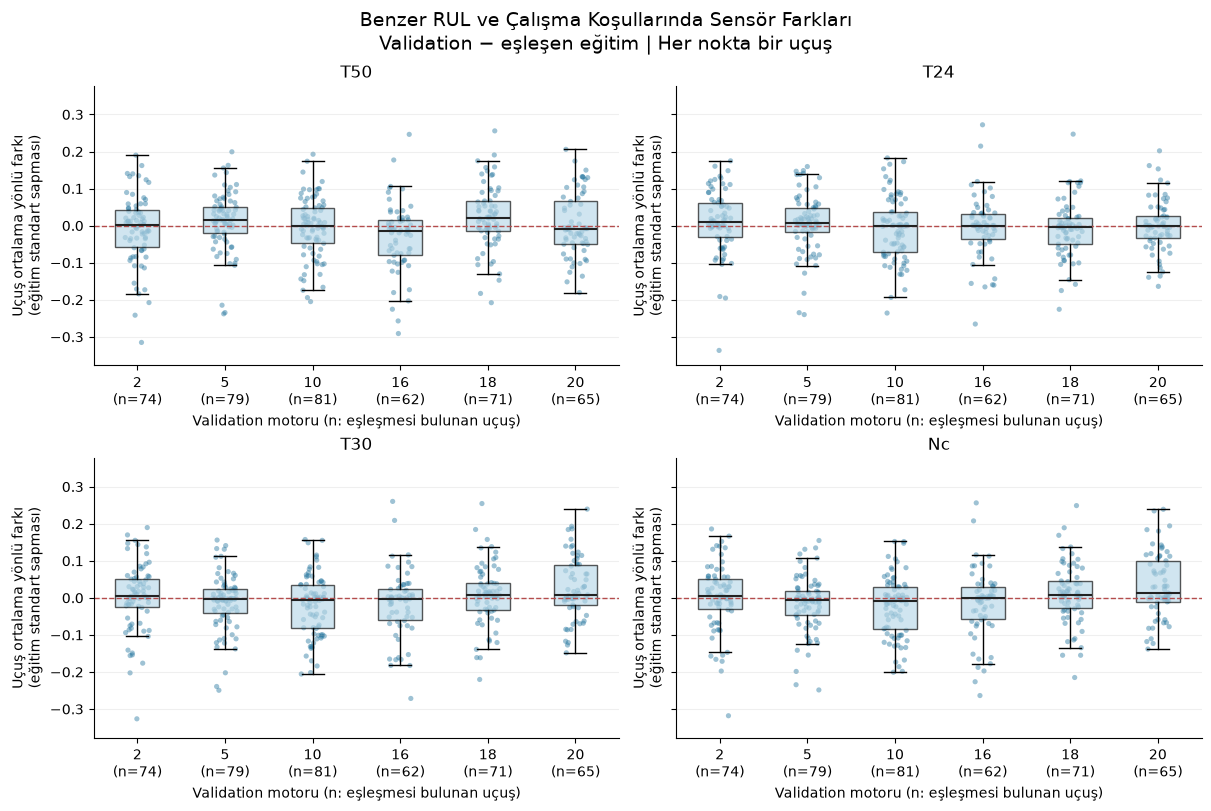

In [7]:
# Önceki hücredeki deprecated parametreye gerek olmadan aynı indeks.
features_by_id = window_features.set_index("window_id")
assert features_by_id.index.is_unique

top_sensors = sensor_ranking.head(4).index.tolist()
engine_order = sorted(DEV_UNITS)
rng = np.random.default_rng(42)

plot_data = sensor_flight_gaps.loc[
    sensor_flight_gaps["sensor"].isin(top_sensors)
]

# Paneller aynı dikey ölçeği kullanır; hiçbir değer kırpılmaz.
plot_limit = max(
    0.01,
    float(plot_data["signed_gap"].abs().max()) * 1.12,
)

fig, axes = plt.subplots(
    2, 2, figsize=(12, 8), sharey=True, constrained_layout=True
)

for ax, sensor in zip(axes.flat, top_sensors):
    groups = [
        plot_data.loc[
            plot_data["sensor"].eq(sensor)
            & plot_data["unit"].eq(unit),
            "signed_gap",
        ].to_numpy()
        for unit in engine_order
    ]
    assert all(len(values) > 0 for values in groups)

    boxes = ax.boxplot(
        groups,
        positions=np.arange(1, len(engine_order) + 1),
        widths=0.5,
        patch_artist=True,
        showfliers=False,  # Bütün uçuşlar aşağıda nokta olarak gösterilir.
        medianprops={"color": "#222222", "linewidth": 1.5},
    )
    for box in boxes["boxes"]:
        box.set_facecolor("#B8D8E8")
        box.set_alpha(0.65)

    for position, values in enumerate(groups, start=1):
        jitter = rng.uniform(-0.14, 0.14, size=len(values))
        ax.scatter(
            position + jitter,
            values,
            s=14,
            alpha=0.45,
            color="#2878A0",
            edgecolors="none",
        )

    ax.axhline(0, color="#B44C4C", linestyle="--", linewidth=1)
    ax.set_xticks(
        np.arange(1, len(engine_order) + 1),
        [f"{unit}\n(n={len(values)})"
         for unit, values in zip(engine_order, groups)],
    )
    ax.set(
        title=sensor,
        xlabel="Validation motoru (n: eşleşmesi bulunan uçuş)",
        ylabel="Uçuş ortalama yönlü farkı\n(eğitim standart sapması)",
        ylim=(-plot_limit, plot_limit),
    )
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Benzer RUL ve Çalışma Koşullarında Sensör Farkları\n"
    "Validation − eşleşen eğitim | Her nokta bir uçuş",
    fontsize=14,
)

plt.show()

## RUL Aralıklarına Göre Sensör Ortalaması ve Değişkenlik Farkları

Mevcut koşul eşleşmeleri korunarak sensör farklılıkları 0–20, 21–40,
41–60 ve 61 ve üzeri RUL aralıklarında karşılaştırılacaktır.
Gruplama validation penceresinin gerçek RUL değerine göre yapılacaktır.

Her sensör için iki özellik incelenecektir:

- Pencere ortalaması: sensör seviyesindeki farklılık.
- Pencere içi standart sapma: 256 örnek içindeki değişkenlik farklılığı.

Her özelliğin eşleşmiş farkı, ilgili fold’un eğitim pencerelerindeki
aynı özelliğin standart sapmasına bölünecektir. Ölçek her fold için
RUL grupları arasında sabit tutulacaktır. Ortalama ve değişkenlik
ölçütleri farklı ölçeklerle standartlaştırıldığından büyüklükleri
birbirleriyle doğrudan karşılaştırılmayacaktır.

Mutlak farklar önce uçuş düzeyinde, sonra motor düzeyinde
ortalanacaktır. Genel tabloda motorlara eşit ağırlık verilecektir.
Motor bazındaki sonuçlar ayrıca saklanacaktır.

Yüksek RUL grubunun motorlara göre kapsamı farklıdır; özellikle Motor
16 yalnızca iki uçuşla temsil edilmektedir. Motor 5’in eğitim RUL
kapsamı dışındaki pencereleri bu karşılaştırmaya dahil değildir.

Pencere içi standart sapma zamansal sıralamayı göstermez. Bu nedenle
değişkenlik farkları, bozulmanın yönü veya ilerleme hızı olarak
yorumlanmayacaktır.

In [8]:
RUL_COMPARISON_LABELS = ["0–20", "21–40", "41–60", "61 ve üzeri"]

rul_matches = accepted_matches.copy()
rul_matches["rul_group"] = pd.cut(
    rul_matches["actual_rul"],
    bins=[0, 20, 40, 60, np.inf],
    labels=RUL_COMPARISON_LABELS,
    include_lowest=True,
    right=True,
)
assert rul_matches["rul_group"].notna().all()

# Önce grupların gerçek karşılaştırma kapsamını göster.
rul_match_coverage = (
    rul_matches.groupby(
        ["validation_unit", "rul_group"], observed=True
    )
    .agg(
        window_count=("window_id", "size"),
        flight_count=("validation_cycle", "nunique"),
    )
    .rename(columns={
        "window_count": "Pencere",
        "flight_count": "Uçuş",
    })
    .unstack("rul_group")
    .rename_axis("Motor")
)
display(rul_match_coverage)

rul_sensor_parts = []

for fold_number, matches in rul_matches.groupby("fold", sort=True):
    train_records, _ = split_windows_by_fold(
        windows, fold_number=int(fold_number)
    )
    train_ids = [record.window_id for record in train_records]

    for suffix, feature_type in [
        ("mean", "Pencere ortalaması"),
        ("std", "Pencere içi standart sapma"),
    ]:
        columns = [f"{sensor}_{suffix}" for sensor in sensor_names]
        scale = features_by_id.loc[train_ids, columns].std(ddof=0)

        assert np.isfinite(scale).all() and scale.gt(0).all(), (
            f"Fold {fold_number}, {feature_type}: geçersiz ölçek."
        )

        validation_values = features_by_id.loc[
            matches["window_id"], columns
        ].to_numpy(dtype=float)
        reference_values = features_by_id.loc[
            matches["matched_window_id"], columns
        ].to_numpy(dtype=float)

        gaps = (validation_values - reference_values) / scale.to_numpy()

        for index, sensor in enumerate(sensor_names):
            rul_sensor_parts.append(pd.DataFrame({
                "unit": matches["validation_unit"].to_numpy(),
                "cycle": matches["validation_cycle"].to_numpy(),
                "rul_group": matches["rul_group"].to_numpy(),
                "sensor": sensor,
                "feature_type": feature_type,
                "signed_gap": gaps[:, index],
                "absolute_gap": np.abs(gaps[:, index]),
            }))

rul_sensor_gaps = pd.concat(rul_sensor_parts, ignore_index=True)
del rul_sensor_parts

assert len(rul_sensor_gaps) == len(accepted_matches) * 14 * 2
assert np.isfinite(
    rul_sensor_gaps[["signed_gap", "absolute_gap"]].to_numpy()
).all()

# Uçuşlara eşit ağırlık vermek için iki aşamalı özet.
rul_sensor_flight = (
    rul_sensor_gaps.groupby(
        ["unit", "cycle", "rul_group", "sensor", "feature_type"],
        observed=True,
        as_index=False,
    )
    .agg(
        signed_gap=("signed_gap", "mean"),
        absolute_gap=("absolute_gap", "mean"),
    )
)

rul_sensor_engine = (
    rul_sensor_flight.groupby(
        ["unit", "rul_group", "sensor", "feature_type"],
        observed=True,
        as_index=False,
    )
    .agg(
        signed_gap=("signed_gap", "mean"),
        absolute_gap=("absolute_gap", "mean"),
        flight_count=("cycle", "nunique"),
    )
)

# Her aralıkta altı motorun da temsil edildiğini doğrula.
assert (
    rul_sensor_engine.groupby(
        ["rul_group", "sensor", "feature_type"], observed=True
    )["unit"].nunique().eq(6).all()
)

rul_sensor_summary = (
    rul_sensor_engine.groupby(
        ["feature_type", "sensor", "rul_group"], observed=True
    )["absolute_gap"]
    .mean()
    .unstack("rul_group")
    .reindex(columns=RUL_COMPARISON_LABELS)
)

for feature_type in [
    "Pencere ortalaması",
    "Pencere içi standart sapma",
]:
    table = (
        rul_sensor_summary.loc[feature_type]
        .reindex(sensor_names)
        .copy()
    )
    table["61+ eksi 41–60"] = table["61 ve üzeri"] - table["41–60"]

    print(f"\n{feature_type} — motorlara eşit ağırlıklı mutlak fark:")
    display(table.round(4))

print(
    "Pozitif '61+ eksi 41–60', yüksek RUL grubunda daha büyük "
    "eşleşmiş fark olduğunu gösterir; nedensel etki değildir."
)

Pencere                         Uçuş                        
rul_group    0–20 21–40 41–60 61 ve üzeri 0–20 21–40 41–60 61 ve üzeri
Motor                                                                 
2             540   594   538         313   21    20    20          13
5             605   583   435         639   21    20    19          19
10            469   440   669         426   20    20    20          21
16            527   563   645          68   21    19    20           2
18            637   646   517         324   21    20    20          10
20            560   551   612         148   20    20    20           5


Pencere ortalaması — motorlara eşit ağırlıklı mutlak fark:


rul_group,0–20,21–40,41–60,61 ve üzeri,61+ eksi 41–60
sensor,,,,,
T24,0.1025,0.1034,0.1037,0.1006,-0.0032
T30,0.1040,0.1026,0.1019,0.0936,-0.0083
T48,0.0955,0.1010,0.0991,0.0964,-0.0027
T50,0.1102,0.1044,0.1044,0.0929,-0.0115
P15,0.0759,0.0741,0.0776,0.0839,0.0063
P2,0.0672,0.0651,0.0675,0.0770,0.0095
P21,0.0759,0.0741,0.0776,0.0839,0.0063
P24,0.0820,0.0810,0.0845,0.0876,0.0031
Ps30,0.0933,0.0905,0.0942,0.0873,-0.0069



Pencere içi standart sapma — motorlara eşit ağırlıklı mutlak fark:


rul_group,0–20,21–40,41–60,61 ve üzeri,61+ eksi 41–60
sensor,,,,,
T24,0.0678,0.0655,0.0657,0.0724,0.0067
T30,0.0568,0.0558,0.0558,0.0607,0.0049
T48,0.0564,0.0542,0.0537,0.0589,0.0052
T50,0.0705,0.0670,0.0674,0.0727,0.0053
P15,0.0707,0.0670,0.0715,0.0771,0.0056
P2,0.0453,0.0457,0.0486,0.0449,-0.0037
P21,0.0707,0.0670,0.0715,0.0771,0.0056
P24,0.0702,0.0668,0.0710,0.0778,0.0069
Ps30,0.0617,0.0596,0.0621,0.0684,0.0063


Pozitif '61+ eksi 41–60', yüksek RUL grubunda daha büyük eşleşmiş fark olduğunu gösterir; nedensel etki değildir.


## Sağlıklı Dönemlerin ve Sağlık Etiketi Geçişlerinin Belirlenmesi

N-CMAPSS sağlık etiketi hs için 1 sağlıklı, 0 sağlıksız durumu ifade
eder. Sağlıklı dönemde normal aşınma bulunabilir; bu dönem değişmeyen
veya tamamen yeni bir motor durumu olarak kabul edilmeyecektir.

Kaynaklar:
- [Veri seti makalesi, Bölüm 4.2](https://www.mdpi.com/2306-5729/6/1/5)
- [N-CMAPSS sağlık etiketi kodlaması](https://papers.phmsociety.org/index.php/ijphm/article/download/3486/2078)

Bu adımda mevcut pencere özetlerindeki hs minimum ve maksimum
değerleri kullanılarak tamamen sağlıklı, tamamen sağlıksız ve
karışık etiketli pencereler belirlenecektir.

Her motor için sağlıklı dönem kapsamı ve ilk hs=0 gözlenen uçuş
raporlanacaktır. Ayrıca sağlıksız etiket sonrasında yeniden sağlıklı
etiket görülüp görülmediği kontrol edilecektir.

Geçiş bilgisi veri seti etiketine dayalıdır; sensörlerden tahmin edilmiş
bir bozulma başlangıcı değildir. Uçuş düzeyindeki sonuçlar yalnızca
metadata pencerelerinin kapsadığı örnekleri temsil eder; uçuş sonundaki
pencere dışı örnekler değerlendirmeye dahil değildir.

hs yalnızca teşhis amacıyla kullanılacaktır. Sağlıklı dönem sensör
karşılaştırması, bir sonraki adımda çalışma koşulları eşleştirilerek
yapılacaktır.

In [9]:
# HDF5 yeniden okunmadan, önceden çıkarılan hs sınırları kullanılır.
assert window_features[["hs_min", "hs_max"]].isin([0, 1]).all().all()
assert window_features["hs_min"].le(window_features["hs_max"]).all()

health_windows = window_features.copy()
health_windows["health_state"] = np.select(
    [
        health_windows["hs_min"].eq(1),
        health_windows["hs_max"].eq(0),
    ],
    ["Sağlıklı", "Sağlıksız"],
    default="Karışık",
)

health_flights = (
    health_windows.groupby(["unit", "cycle"], as_index=False)
    .agg(
        rul=("rul", "first"),
        hs_min=("hs_min", "min"),
        hs_max=("hs_max", "max"),
        window_count=("window_id", "size"),
    )
    .sort_values(["unit", "cycle"])
)

health_flights["health_state"] = np.select(
    [
        health_flights["hs_min"].eq(1),
        health_flights["hs_max"].eq(0),
    ],
    ["Sağlıklı", "Sağlıksız"],
    default="Karışık",
)

health_summary_rows = []

for unit in sorted(DEV_UNITS):
    engine_windows = health_windows.loc[
        health_windows["unit"].eq(unit)
    ].sort_values("start_row")

    engine_flights = health_flights.loc[
        health_flights["unit"].eq(unit)
    ]

    healthy_flights = engine_flights.loc[
        engine_flights["health_state"].eq("Sağlıklı")
    ]
    first_zero_candidates = engine_flights.loc[
        engine_flights["hs_min"].eq(0)
    ]
    first_zero_cycle = (
        int(first_zero_candidates["cycle"].min())
        if len(first_zero_candidates) else np.nan
    )

    # Pencere sırasına göre: önceki bir pencerede 0 görülmüşken
    # sonraki bir pencerede 1 bulunuyor mu?
    zero_seen_before = (
        engine_windows["hs_min"].eq(0)
        .cummax()
        .shift(fill_value=False)
    )
    return_to_one = (
        zero_seen_before & engine_windows["hs_max"].eq(1)
    ).sum()

    health_summary_rows.append({
        "Motor": unit,
        "Sağlıklı pencere": engine_windows["health_state"].eq("Sağlıklı").sum(),
        "Sağlıksız pencere": engine_windows["health_state"].eq("Sağlıksız").sum(),
        "Karışık pencere": engine_windows["health_state"].eq("Karışık").sum(),
        "Sağlıklı uçuş": len(healthy_flights),
        "Sağlıksız uçuş": engine_flights["health_state"].eq("Sağlıksız").sum(),
        "Karışık uçuş": engine_flights["health_state"].eq("Karışık").sum(),
        "İlk sağlıklı uçuş": healthy_flights["cycle"].min(),
        "Son sağlıklı uçuş": healthy_flights["cycle"].max(),
        "İlk hs=0 görülen uçuş": first_zero_cycle,
        "Sağlıklı minimum RUL": healthy_flights["rul"].min(),
        "Sağlıklı maksimum RUL": healthy_flights["rul"].max(),
        "Önceki hs=0 sonrası 1 içeren pencere": int(return_to_one),
    })

health_summary = pd.DataFrame(health_summary_rows).set_index("Motor")

assert health_summary[
    ["Sağlıklı pencere", "Sağlıksız pencere", "Karışık pencere"]
].to_numpy().sum() == len(window_features)

assert health_summary[
    ["Sağlıklı uçuş", "Sağlıksız uçuş", "Karışık uçuş"]
].to_numpy().sum() == len(flights)

display(health_summary)

print("Sağlık etiketleri yalnızca analiz için kullanıldı.")
print("Geçiş zamanları sensörlerden çıkarılmadı; hs etiketinden belirlendi.")

,Sağlıklı pencere,Sağlıksız pencere,Karışık pencere,Sağlıklı uçuş,Sağlıksız uçuş,Karışık uçuş,İlk sağlıklı uçuş,Son sağlıklı uçuş,İlk hs=0 görülen uçuş,Sağlıklı minimum RUL,Sağlıklı maksimum RUL,Önceki hs=0 sonrası 1 içeren pencere
Motor,,,,,,,,,,,,
2,729,2565,0,16,59,0,1,16,17,59.0,74.0,0
5,728,3262,0,16,73,0,1,16,17,73.0,88.0,0
10,727,2958,0,16,66,0,1,16,17,66.0,81.0,0
16,751,2204,0,15,48,0,1,15,16,48.0,62.0,0
18,746,2700,0,16,55,0,1,16,17,55.0,70.0,0
20,748,2221,0,16,50,0,1,16,17,50.0,65.0,0


Sağlık etiketleri yalnızca analiz için kullanıldı.
Geçiş zamanları sensörlerden çıkarılmadı; hs etiketinden belirlendi.


## Benzer Uçuş Yaşı ve Koşullarda Sağlıklı Motorların Karşılaştırılması

Motorların sağlıklı dönemleri ilk 15–16 uçuşta bulunmasına rağmen
bu dönemlerin RUL aralıkları farklıdır. Altı motorun ortak sağlıklı
RUL aralığı yoktur.

Bu nedenle sağlıklı çalışma karakteristikleri karşılaştırılırken
iki pencerenin de tamamen sağlıklı olması, uçuş numaralarının en
fazla 2 farklı olması ve çalışma koşullarının benzerliği aranacaktır.
RUL bu eşleştirmede kullanılmayacaktır.

Önceki yöntemdeki sekiz koşul özeti ve 0,25 standartlaştırılmış
fark sınırı korunacaktır. Ölçekler ilgili fold’un bütün eğitim
pencerelerinden hesaplanarak önceki analizle tutarlı tutulacaktır.
Aday araması ise yalnızca sağlıklı eğitim pencerelerinde yapılacaktır.

Sensör ortalamalarının ve pencere içi standart sapmalarının yönlü ve
mutlak farkları hesaplanacaktır. Özetlerde önce uçuşlara, ardından
motorlara eşit ağırlık verilecektir.

Bu analiz, sağlıklı dönemdeki farklılıkların varlığını inceler.
Farkların ilk kurulumdan itibaren mevcut olduğunu veya sabit bir
motor ofseti olduğunu tek başına göstermez. Healthy Baseline
Normalization ancak koşullar kontrol edildikten sonra kalan farkların
yönü ve zaman içindeki kararlılığı da dikkate alınarak değerlendirilebilir.

hs burada yalnızca geçmiş verinin teşhis amaçlı seçimi için kullanılır;
gerçek uygulamada validation motorunun sağlık etiketlerinin bilindiği
varsayılmaz.

In [10]:
HEALTHY_CYCLE_TOLERANCE = 2
healthy_match_parts = []
healthy_gap_parts = []
healthy_coverage_rows = []

for fold_number in range(1, 7):
    train_records, validation_records = split_windows_by_fold(
        windows, fold_number=fold_number
    )
    train_ids = [record.window_id for record in train_records]
    validation_ids = [record.window_id for record in validation_records]

    train_all = features_by_id.loc[train_ids]
    validation_all = features_by_id.loc[validation_ids]

    train_healthy = train_all.loc[train_all["hs_min"].eq(1)]
    validation_healthy = validation_all.loc[
        validation_all["hs_min"].eq(1)
    ]
    assert not train_healthy.empty and not validation_healthy.empty

    center = train_all[matching_columns].mean()
    scale = train_all[matching_columns].std(ddof=0)
    assert scale.gt(0).all()

    fold_candidates = []

    for cycle, query in validation_healthy.groupby("cycle"):
        candidates = train_healthy.loc[
            train_healthy["cycle"].sub(cycle).abs().le(
                HEALTHY_CYCLE_TOLERANCE
            )
        ]
        if candidates.empty:
            continue

        search = NearestNeighbors(n_neighbors=1, metric="chebyshev")
        search.fit(
            ((candidates[matching_columns] - center) / scale).to_numpy()
        )
        distances, positions = search.kneighbors(
            ((query[matching_columns] - center) / scale).to_numpy()
        )
        matched = candidates.iloc[positions[:, 0]]

        fold_candidates.append(pd.DataFrame({
            "fold": fold_number,
            "unit": query["unit"].to_numpy(),
            "cycle": query["cycle"].to_numpy(),
            "window_id": query.index.to_numpy(),
            "matched_window_id": matched.index.to_numpy(),
            "matched_unit": matched["unit"].to_numpy(),
            "cycle_gap": np.abs(
                query["cycle"].to_numpy() - matched["cycle"].to_numpy()
            ),
            "condition_gap": distances[:, 0],
        }))

    assert fold_candidates, f"Fold {fold_number}: sağlıklı aday bulunamadı."
    candidates = pd.concat(fold_candidates, ignore_index=True)
    selected = candidates.loc[
        candidates["condition_gap"].le(CONDITION_MATCH_THRESHOLD)
    ].copy()
    assert not selected.empty, f"Fold {fold_number}: kabul edilen eşleşme yok."

    healthy_match_parts.append(selected)
    reuse = selected["matched_window_id"].value_counts()

    healthy_coverage_rows.append({
        "Motor": int(validation_healthy["unit"].iloc[0]),
        "Sağlıklı pencere": len(validation_healthy),
        "Eşleşen pencere": len(selected),
        "Korunan (%)": 100 * len(selected) / len(validation_healthy),
        "Korunan uçuş": selected["cycle"].nunique(),
        "Sağlıklı uçuş": validation_healthy["cycle"].nunique(),
        "Eşleşen eğitim motoru": selected["matched_unit"].nunique(),
        "En yüksek tekrar": int(reuse.max()),
    })

    for suffix, feature_type in [
        ("mean", "Pencere ortalaması"),
        ("std", "Pencere içi standart sapma"),
    ]:
        columns = [f"{sensor}_{suffix}" for sensor in sensor_names]
        sensor_scale = train_all[columns].std(ddof=0)
        assert np.isfinite(sensor_scale).all() and sensor_scale.gt(0).all()

        gaps = (
            features_by_id.loc[selected["window_id"], columns].to_numpy()
            - features_by_id.loc[
                selected["matched_window_id"], columns
            ].to_numpy()
        ) / sensor_scale.to_numpy()

        for index, sensor in enumerate(sensor_names):
            healthy_gap_parts.append(pd.DataFrame({
                "unit": selected["unit"].to_numpy(),
                "cycle": selected["cycle"].to_numpy(),
                "sensor": sensor,
                "feature_type": feature_type,
                "signed_gap": gaps[:, index],
                "absolute_gap": np.abs(gaps[:, index]),
            }))

healthy_matches = pd.concat(healthy_match_parts, ignore_index=True)
healthy_sensor_gaps = pd.concat(healthy_gap_parts, ignore_index=True)
del healthy_match_parts, healthy_gap_parts

assert healthy_matches["window_id"].is_unique
assert healthy_matches["unit"].ne(healthy_matches["matched_unit"]).all()
assert healthy_matches["cycle_gap"].le(HEALTHY_CYCLE_TOLERANCE).all()
assert np.isfinite(
    healthy_sensor_gaps[["signed_gap", "absolute_gap"]].to_numpy()
).all()

healthy_sensor_flight = (
    healthy_sensor_gaps.groupby(
        ["unit", "cycle", "sensor", "feature_type"], as_index=False
    )[["signed_gap", "absolute_gap"]].mean()
)
healthy_sensor_engine = (
    healthy_sensor_flight.groupby(
        ["unit", "sensor", "feature_type"], as_index=False
    )[["signed_gap", "absolute_gap"]].mean()
)

print("Sağlıklı dönem eşleşme kapsamı:")
display(
    pd.DataFrame(healthy_coverage_rows)
    .set_index("Motor").round(2)
)

print("Motorlara eşit ağırlıklı mutlak sensör farkları:")
healthy_sensor_summary = (
    healthy_sensor_engine.groupby(["sensor", "feature_type"])
    ["absolute_gap"].mean().unstack("feature_type")
    .reindex(sensor_names)
)
display(healthy_sensor_summary.round(4))

print("Sağlıklı pencere ortalamalarının motor bazında yönlü farkları:")
healthy_signed_means = (
    healthy_sensor_engine.loc[
        healthy_sensor_engine["feature_type"].eq("Pencere ortalaması")
    ]
    .pivot(index="sensor", columns="unit", values="signed_gap")
    .reindex(sensor_names)
)
display(healthy_signed_means.round(4))

Sağlıklı dönem eşleşme kapsamı:


,Sağlıklı pencere,Eşleşen pencere,Korunan (%),Korunan uçuş,Sağlıklı uçuş,Eşleşen eğitim motoru,En yüksek tekrar
Motor,,,,,,,
2,729,359,49.25,16,16,5,20
5,728,482,66.21,16,16,5,12
10,727,419,57.63,16,16,5,7
16,751,505,67.24,15,15,5,15
18,746,459,61.53,16,16,5,17
20,748,414,55.35,16,16,5,15


Motorlara eşit ağırlıklı mutlak sensör farkları:


feature_type,Pencere içi standart sapma,Pencere ortalaması
sensor,,
T24,0.0708,0.1116
T30,0.0579,0.1066
T48,0.0553,0.1029
T50,0.0703,0.1044
P15,0.0757,0.0801
P2,0.0509,0.0686
P21,0.0757,0.0801
P24,0.0746,0.0873
Ps30,0.0650,0.0953


Sağlıklı pencere ortalamalarının motor bazında yönlü farkları:


unit,2,5,10,16,18,20
sensor,,,,,,
T24,0.0403,-0.0401,0.0047,0.0041,-0.0106,-0.0128
T30,0.0467,-0.0436,0.0028,0.0061,-0.0220,-0.0081
T48,0.0385,-0.0410,0.0070,0.0162,-0.0287,-0.0101
T50,0.0335,-0.0459,0.0056,0.0268,-0.0215,-0.0191
P15,0.0223,-0.0285,-0.0023,0.0019,0.0001,-0.0088
P2,0.0127,-0.0209,-0.0031,0.0009,0.0073,-0.0087
P21,0.0223,-0.0285,-0.0023,0.0019,0.0001,-0.0088
P24,0.0275,-0.0324,-0.0012,0.0024,-0.0043,-0.0089
Ps30,0.0379,-0.0393,-0.0013,0.0045,-0.0138,-0.0079


## Bozulma Trendleri İçin Sağlıklı Referansa Göre Sensör Farkları

Her validation motorunun bütün uçuşları, ilgili fold’un yalnızca
eğitim motorlarından oluşturulan sağlıklı referans havuzuyla
karşılaştırılacaktır. Referans havuzu motor ömrü boyunca sabit kalacak,
eşleşen referans penceresi çalışma koşullarına göre seçilecektir.

Bu aşamada RUL veya uçuş yaşı eşleştirme koşulu olmayacaktır.
Böylece yaşla birlikte gelişen sensör değişimleri eşleştirme yoluyla
ortadan kaldırılmayacaktır.

Önceki sekiz koşul özeti ve 0,25 eşleşme sınırı korunacaktır.
Sensör ortalamaları ve pencere içi standart sapmaları için referansa
göre farklar, ilgili eğitim özelliğinin standart sapmasına bölünecektir.
Ardından kabul edilen pencerelerin yönlü farkları uçuş bazında
ortalanacaktır.

Bu farklar koşulların etkisini azaltmayı amaçlar; koşul etkisinin
tamamen giderildiği varsayılmaz. Eşleşen pencere kapsamının uçuşlar
boyunca değişmesi görünür bir trend oluşturabileceğinden, önce
sağlıklı ve sağlıksız dönemlerin kapsama oranları kontrol edilecektir.
Eşleşmesi olmayan uçuşlara değer atanmayacaktır.

hs yalnızca eğitim referansının seçimi ve dönemlerin teşhis amaçlı
karşılaştırılması için kullanılır. Validation sağlık etiketleri
eşleşme seçiminde kullanılmaz. Bu çalışma bir normalizasyon
yönteminin performans doğrulaması değildir.

In [11]:
trend_match_parts = []
trend_flight_parts = []
trend_columns = [
    f"{sensor}_{suffix}"
    for suffix in ["mean", "std"]
    for sensor in sensor_names
]
residual_columns = [f"{column}_residual" for column in trend_columns]

for fold_number in range(1, 7):
    train_records, validation_records = split_windows_by_fold(
        windows, fold_number=fold_number
    )
    train_all = features_by_id.loc[
        [record.window_id for record in train_records]
    ]
    query = features_by_id.loc[
        [record.window_id for record in validation_records]
    ]

    # Sağlıklı referans yalnızca diğer beş motordan gelir.
    reference = train_all.loc[train_all["hs_min"].eq(1)]
    assert not reference.empty
    assert set(reference["unit"]).isdisjoint(query["unit"])

    condition_center = train_all[matching_columns].mean()
    condition_scale = train_all[matching_columns].std(ddof=0)
    feature_scale = train_all[trend_columns].std(ddof=0)

    assert condition_scale.gt(0).all()
    assert feature_scale.gt(0).all()

    search = NearestNeighbors(n_neighbors=1, metric="chebyshev")
    search.fit(
        ((reference[matching_columns] - condition_center)
         / condition_scale).to_numpy()
    )
    distances, positions = search.kneighbors(
        ((query[matching_columns] - condition_center)
         / condition_scale).to_numpy()
    )

    keep = distances[:, 0] <= CONDITION_MATCH_THRESHOLD
    selected = query.iloc[np.flatnonzero(keep)]
    matched = reference.iloc[positions[keep, 0]]
    assert not selected.empty, f"Fold {fold_number}: eşleşme bulunamadı."

    matches = pd.DataFrame({
        "fold": fold_number,
        "unit": selected["unit"].to_numpy(),
        "cycle": selected["cycle"].to_numpy(),
        "window_id": selected.index.to_numpy(),
        "matched_window_id": matched.index.to_numpy(),
        "matched_unit": matched["unit"].to_numpy(),
        "condition_gap": distances[keep, 0],
    })
    trend_match_parts.append(matches)

    # Aynı eğitim ölçeği motorun bütün uçuşları için sabittir.
    residuals = (
        selected[trend_columns].to_numpy(dtype=float)
        - matched[trend_columns].to_numpy(dtype=float)
    ) / feature_scale.to_numpy()
    assert np.isfinite(residuals).all()

    residual_frame = pd.DataFrame(residuals, columns=residual_columns)
    residual_frame["unit"] = selected["unit"].to_numpy()
    residual_frame["cycle"] = selected["cycle"].to_numpy()

    trend_flight_parts.append(
        residual_frame.groupby(["unit", "cycle"], as_index=False)
        [residual_columns].mean()
    )

trend_matches = pd.concat(trend_match_parts, ignore_index=True)
trend_residuals = pd.concat(trend_flight_parts, ignore_index=True)
del trend_match_parts, trend_flight_parts

assert trend_matches["window_id"].is_unique
assert not trend_residuals.duplicated(["unit", "cycle"]).any()

matched_counts = (
    trend_matches.groupby(["unit", "cycle"])
    .size().rename("matched_windows").reset_index()
)

# Bütün uçuşları koru; eşleşmeyenlerin sensör farkları NaN kalır.
trend_flights = (
    health_flights.merge(
        matched_counts, on=["unit", "cycle"], how="left",
        validate="one_to_one",
    )
    .merge(
        trend_residuals, on=["unit", "cycle"], how="left",
        validate="one_to_one",
    )
    .sort_values(["unit", "cycle"])
    .reset_index(drop=True)
)
trend_flights["matched_windows"] = (
    trend_flights["matched_windows"].fillna(0).astype(int)
)
trend_flights["coverage_pct"] = (
    100 * trend_flights["matched_windows"] / trend_flights["window_count"]
)

assert len(trend_flights) == len(health_flights)
assert trend_flights["coverage_pct"].between(0, 100).all()

trend_coverage = (
    trend_flights.groupby(["unit", "health_state"], observed=True)
    .agg(
        total_flights=("cycle", "size"),
        covered_flights=("matched_windows", lambda x: x.gt(0).sum()),
        total_windows=("window_count", "sum"),
        matched_windows=("matched_windows", "sum"),
        median_flight_coverage=("coverage_pct", "median"),
        minimum_flight_coverage=("coverage_pct", "min"),
    )
)
trend_coverage["window_coverage_pct"] = (
    100 * trend_coverage["matched_windows"] / trend_coverage["total_windows"]
)

display(trend_coverage.rename(columns={
    "total_flights": "Toplam uçuş",
    "covered_flights": "Eşleşen uçuş",
    "total_windows": "Toplam pencere",
    "matched_windows": "Eşleşen pencere",
    "median_flight_coverage": "Uçuş kapsamı medyanı (%)",
    "minimum_flight_coverage": "En düşük uçuş kapsamı (%)",
    "window_coverage_pct": "Pencere kapsamı (%)",
}).round(2))

print("Uçuş bazlı referans farkları hazır: 14 sensör × 2 özet özellik.")
print("Eşleşmeyen uçuşlar doldurulmadı; henüz trend eğimi hesaplanmadı.")

Toplam uçuş  Eşleşen uçuş  Toplam pencere  Eşleşen pencere  \
unit health_state                                                               
2    Sağlıklı               16            16             729              547   
     Sağlıksız              59            59            2565             2105   
5    Sağlıklı               16            16             728              569   
     Sağlıksız              73            73            3262             2567   
10   Sağlıklı               16            16             727              589   
     Sağlıksız              66            66            2958             2370   
16   Sağlıklı               15            15             751              618   
     Sağlıksız              48            48            2204             1811   
18   Sağlıklı               16            16             746              614   
     Sağlıksız              55            55            2700             2009   
20   Sağlıklı               16            16             748              541   
     Sağlıksız              50            50            2221             1728   

                   Uçuş kapsamı medyanı (%)  En düşük uçuş kapsamı (%)  \
unit health_state                                                        
2    Sağlıklı                         77.06                      37.93   
     Sağlıksız                        84.62                       5.36   
5    Sağlıklı                         75.68                      55.88   
     Sağlıksız                        76.00                      43.59   
10   Sağlıklı                         88.24                      24.24   
     Sağlıksız                        86.69                      33.33   
16   Sağlıklı                        100.00                      25.45   
     Sağlıksız                        82.46                      19.51   
18   Sağlıklı                         79.22                      40.00   
     Sağlıksız                        75.61                       7.14   
20   Sağlıklı                         71.27                      38.64   
     Sağlıksız                        76.19                      22.22   

                   Pencere kapsamı (%)  
unit health_state                       
2    Sağlıklı                    75.03  
     Sağlıksız                   82.07  
5    Sağlıklı                    78.16  
     Sağlıksız                   78.69  
10   Sağlıklı                    81.02  
     Sağlıksız                   80.12  
16   Sağlıklı                    82.29  
     Sağlıksız                   82.17  
18   Sağlıklı                    82.31  
     Sağlıksız                   74.41  
20   Sağlıklı                    72.33  
     Sağlıksız                   77.80

Uçuş bazlı referans farkları hazır: 14 sensör × 2 özet özellik.
Eşleşmeyen uçuşlar doldurulmadı; henüz trend eğimi hesaplanmadı.


## Sağlıklı ve Sağlıksız Dönemlerde Sensör Trendlerinin Karşılaştırılması

Sağlıklı referansa göre hesaplanan uçuş düzeyindeki sensör farklarının
uçuş numarasıyla ilişkisi, her motor ve sağlık dönemi için ayrı
doğrusal eğimlerle özetlenecektir.

Pozitif eğim, referansa göre sensör farkının uçuşlar boyunca arttığını;
negatif eğim azaldığını gösterir. Pencere içi standart sapmanın eğimi
ise sensör değişkenliğinin zaman içindeki yönünü ifade eder.

Eğimler, ilgili eğitim özelliğinin standart sapması / uçuş birimindedir.
Sağlıklı ve sağlıksız dönemler aynı motor içinde aynı ölçeği kullanır.
Fold’ların ölçekleri farklı olduğundan motorlar arasındaki hız
karşılaştırmaları standartlaştırılmış değişim olarak yorumlanacaktır.

Her uçuş eşit ağırlık alacaktır. Düşük eşleşme kapsamının etkisini
görmek için sonuçlar bütün uçuşlarda ve en az %50 pencere kapsamı
bulunan uçuşlarda ayrı hesaplanacaktır. Bu eşik keşif amaçlıdır.

Doğrusal eğim, dönem boyunca ortalama değişimi özetler; doğrusal olmayan
bozulmayı, yerel hızlanmaları veya başlangıç zamanını tek başına
belirlemez. Sağlık dönemlerinin sınırı mevcut hs etiketinden alınır.
R² yalnızca doğrusal özetin uyumunu gösterir; anlamlılık veya
nedensellik ölçütü değildir.

In [12]:
TREND_COVERAGE_THRESHOLD = 50.0
MIN_TREND_FLIGHTS = 5

trend_fit_rows = []

for selection, coverage_threshold in [
    ("Bütün uçuşlar", 0.0),
    ("Kapsam ≥%50", TREND_COVERAGE_THRESHOLD),
]:
    eligible = trend_flights.loc[
        trend_flights["matched_windows"].gt(0)
        & trend_flights["coverage_pct"].ge(coverage_threshold)
    ]

    for (unit, health_state), group in eligible.groupby(
        ["unit", "health_state"], observed=True
    ):
        for suffix, feature_type in [
            ("mean", "Pencere ortalaması"),
            ("std", "Pencere içi standart sapma"),
        ]:
            for sensor in sensor_names:
                column = f"{sensor}_{suffix}_residual"
                valid = group[["cycle", column]].dropna().sort_values("cycle")

                slope = np.nan
                r_squared = np.nan

                if len(valid) >= MIN_TREND_FLIGHTS:
                    x = valid["cycle"].to_numpy(dtype=float)
                    y = valid[column].to_numpy(dtype=float)
                    x_centered = x - x.mean()

                    slope = np.dot(x_centered, y - y.mean()) / np.dot(
                        x_centered, x_centered
                    )
                    fitted = y.mean() + slope * x_centered
                    total_ss = np.sum((y - y.mean()) ** 2)

                    if total_ss > 0:
                        r_squared = 1 - np.sum((y - fitted) ** 2) / total_ss

                trend_fit_rows.append({
                    "selection": selection,
                    "unit": unit,
                    "health_state": health_state,
                    "sensor": sensor,
                    "feature_type": feature_type,
                    "flight_count": len(valid),
                    "first_cycle": valid["cycle"].min(),
                    "last_cycle": valid["cycle"].max(),
                    "slope": slope,
                    "r_squared": r_squared,
                })

trend_fits = pd.DataFrame(trend_fit_rows)

# Her motor/dönem için hesaplamaya giren uçuş sayısını göster.
fit_coverage = (
    trend_fits.loc[
        trend_fits["sensor"].eq(sensor_names[0])
        & trend_fits["feature_type"].eq("Pencere ortalaması")
    ]
    .pivot(
        index=["unit", "health_state"],
        columns="selection",
        values="flight_count",
    )
)
print("Eğim hesabında kullanılan uçuş sayıları:")
display(fit_coverage)

# Bütün sensörler saklanır; kısa özette motorlar arasındaki
# en büyük sağlıksız dönem eğim aralığına sahip dört sensör gösterilir.
for feature_type in [
    "Pencere ortalaması",
    "Pencere içi standart sapma",
]:
    selected_fits = trend_fits.loc[
        trend_fits["feature_type"].eq(feature_type)
    ]

    slopes = selected_fits.pivot(
        index=["sensor", "unit"],
        columns=["selection", "health_state"],
        values="slope",
    )

    summary = pd.DataFrame(index=slopes.index)
    summary["Sağlıklı eğim — tümü"] = slopes[
        ("Bütün uçuşlar", "Sağlıklı")
    ]
    summary["Sağlıksız eğim — tümü"] = slopes[
        ("Bütün uçuşlar", "Sağlıksız")
    ]
    summary["Sağlıklı eğim — ≥%50"] = slopes[
        ("Kapsam ≥%50", "Sağlıklı")
    ]
    summary["Sağlıksız eğim — ≥%50"] = slopes[
        ("Kapsam ≥%50", "Sağlıksız")
    ]

    summary["Dönemler arası eğim farkı — ≥%50"] = (
        summary["Sağlıksız eğim — ≥%50"]
        - summary["Sağlıklı eğim — ≥%50"]
    )

    r2 = (
        selected_fits.loc[
            selected_fits["selection"].eq("Kapsam ≥%50")
            & selected_fits["health_state"].eq("Sağlıksız")
        ]
        .set_index(["sensor", "unit"])["r_squared"]
    )
    summary["Sağlıksız R² — ≥%50"] = r2

    # En az beş uçuş bulunmayan gruplarda sonuç üretme.
    spread = (
        summary["Sağlıksız eğim — ≥%50"]
        .groupby(level="sensor")
        .agg(["min", "max", "count"])
    )
    spread["range"] = spread["max"] - spread["min"]
    leading_sensors = (
        spread.loc[spread["count"].eq(6)]
        .sort_values("range", ascending=False)
        .head(4).index.tolist()
    )

    print(f"\n{feature_type}:")
    print("Motorlar arası sağlıksız eğim farkı en yüksek dört sensör:")
    display(
        summary.reindex(pd.MultiIndex.from_product(
            [leading_sensors, sorted(DEV_UNITS)],
            names=["sensor", "unit"],
        )).round(5)
    )

print(
    "14 sensörün iki özellik türüne ait bütün sonuçları "
    "'trend_fits' içinde saklandı."
)

Eğim hesabında kullanılan uçuş sayıları:


selection          Bütün uçuşlar  Kapsam ≥%50
unit health_state                            
2    Sağlıklı                 16           13
     Sağlıksız                59           57
5    Sağlıklı                 16           16
     Sağlıksız                73           68
10   Sağlıklı                 16           14
     Sağlıksız                66           56
16   Sağlıklı                 15           12
     Sağlıksız                48           44
18   Sağlıklı                 16           15
     Sağlıksız                55           49
20   Sağlıklı                 16           15
     Sağlıksız                50           44


Pencere ortalaması:
Motorlar arası sağlıksız eğim farkı en yüksek dört sensör:


Sağlıklı eğim — tümü  Sağlıksız eğim — tümü  \
sensor unit                                                
T50    2                 -0.00121                0.00797   
       5                  0.00347                0.00685   
       10                 0.00110                0.00680   
       16                 0.00118                0.00902   
       18                 0.00240                0.00995   
       20                 0.00372                0.01190   
Nc     2                 -0.00210               -0.00196   
       5                  0.00327               -0.00102   
       10                 0.00050               -0.00180   
       16                 0.00018               -0.00259   
       18                 0.00010               -0.00071   
       20                 0.00216                0.00047   
T30    2                 -0.00203               -0.00089   
       5                  0.00340               -0.00019   
       10                 0.00058               -0.00088   
       16                 0.00035               -0.00125   
       18                 0.00030                0.00013   
       20                 0.00233                0.00121   
P40    2                 -0.00181               -0.00061   
       5                  0.00208               -0.00012   
       10                 0.00009               -0.00058   
       16                 0.00070               -0.00100   
       18                 0.00032                0.00028   
       20                 0.00157                0.00098   

             Sağlıklı eğim — ≥%50  Sağlıksız eğim — ≥%50  \
sensor unit                                                
T50    2                 -0.00078                0.00800   
       5                  0.00347                0.00696   
       10                 0.00149                0.00681   
       16                 0.00375                0.00862   
       18                 0.00274                0.00965   
       20                 0.00317                0.01102   
Nc     2                 -0.00165               -0.00201   
       5                  0.00327               -0.00096   
       10                 0.00093               -0.00156   
       16                 0.00280               -0.00287   
       18                 0.00037               -0.00104   
       20                 0.00176                0.00031   
T30    2                 -0.00157               -0.00094   
       5                  0.00340               -0.00012   
       10                 0.00100               -0.00065   
       16                 0.00297               -0.00162   
       18                 0.00058               -0.00021   
       20                 0.00192                0.00101   
P40    2                 -0.00136               -0.00064   
       5                  0.00208               -0.00008   
       10                 0.00042               -0.00040   
       16                 0.00330               -0.00119   
       18                 0.00059               -0.00004   
       20                 0.00124                0.00077   

             Dönemler arası eğim farkı — ≥%50  Sağlıksız R² — ≥%50  
sensor unit                                                         
T50    2                              0.00878              0.74756  
       5                              0.00349              0.73220  
       10                             0.00532              0.73621  
       16                             0.00487              0.79918  
       18                             0.00691              0.78846  
       20                             0.00786              0.79157  
Nc     2                             -0.00036              0.31421  
       5                             -0.00422              0.11436  
       10                            -0.00248              0.43691  
       16                            -0.00567              0.48154  
       18                            -0.00141              0.10


Pencere içi standart sapma:
Motorlar arası sağlıksız eğim farkı en yüksek dört sensör:


Sağlıklı eğim — tümü  Sağlıksız eğim — tümü  \
sensor unit                                                
P24    2                 -0.00071                0.00029   
       5                  0.00132               -0.00003   
       10                -0.00450                0.00016   
       16                -0.00131               -0.00009   
       18                 0.00038                0.00039   
       20                -0.00345               -0.00007   
T24    2                  0.00009                0.00022   
       5                  0.00090                0.00001   
       10                -0.00341                0.00012   
       16                -0.00079               -0.00013   
       18                 0.00023                0.00012   
       20                -0.00208               -0.00008   
P21    2                 -0.00076                0.00021   
       5                  0.00084               -0.00007   
       10                -0.00453                0.00013   
       16                -0.00104               -0.00015   
       18                 0.00031                0.00043   
       20                -0.00427               -0.00003   
P15    2                 -0.00076                0.00021   
       5                  0.00084               -0.00007   
       10                -0.00453                0.00013   
       16                -0.00104               -0.00015   
       18                 0.00031                0.00043   
       20                -0.00427               -0.00003   

             Sağlıklı eğim — ≥%50  Sağlıksız eğim — ≥%50  \
sensor unit                                                
P24    2                 -0.00077                0.00035   
       5                  0.00132               -0.00001   
       10                -0.00409                0.00017   
       16                -0.00074                0.00013   
       18                 0.00031                0.00026   
       20                -0.00304               -0.00035   
T24    2                 -0.00007                0.00031   
       5                  0.00090                0.00003   
       10                -0.00387                0.00017   
       16                -0.00014                0.00009   
       18                 0.00009                0.00007   
       20                -0.00174               -0.00035   
P21    2                 -0.00076                0.00026   
       5                  0.00084               -0.00007   
       10                -0.00365                0.00011   
       16                -0.00086               -0.00001   
       18                 0.00031                0.00028   
       20                -0.00375               -0.00032   
P15    2                 -0.00076                0.00026   
       5                  0.00084               -0.00007   
       10                -0.00365                0.00011   
       16                -0.00086               -0.00001   
       18                 0.00031                0.00028   
       20                -0.00375               -0.00032   

             Dönemler arası eğim farkı — ≥%50  Sağlıksız R² — ≥%50  
sensor unit                                                         
P24    2                              0.00112              0.06132  
       5                             -0.00133              0.00010  
       10                             0.00426              0.04150  
       16                             0.00087              0.01304  
       18                            -0.00005              0.03086  
       20                             0.00269              0.04783  
T24    2                              0.00037              0.07350  
       5                             -0.00087              0.00079  
       10                             0.00403              0.05831  
       16                             0.00023              0.01171  
       18                            -0.00002              0.00

14 sensörün iki özellik türüne ait bütün sonuçları 'trend_fits' içinde saklandı.


## T50 Trendinin Ortak Geçiş Sonrası Zaman Aralığında İncelenmesi

T50’nin sağlıklı referansa göre farkı, bütün motorlarda sağlıksız
dönem boyunca artmaktadır. Ancak motorların sağlıksız dönem uzunlukları
farklı olduğundan, bütün dönem eğimlerinin karşılaştırılması aynı
ilerleme aşamalarını temsil etmeyebilir.

Bu adımda ilk hs=0 görülen uçuş, geçiş sonrası birinci uçuş olarak
tanımlanacaktır. Bütün motorlarda bulunan ilk 40 uçuş, 1–20 ve 21–40
bölümlerine ayrılacaktır. Her bölümde T50 farkının doğrusal eğimi
ve R² değeri hesaplanacaktır.

Önceki kapsam kontrolü korunarak yalnızca en az %50 eşleşme kapsamına
sahip uçuşlar kullanılacaktır. Eksik uçuşlar doldurulmayacak; her
bölümün gözlem sayısı ve kullanılan zaman aralığı raporlanacaktır.

Aynı motor içinde ikinci bölümün daha yüksek pozitif eğimi, bu
aralıkta daha hızlı sensör değişimiyle uyumludur. Bunun fiziksel
bozulma hızlanması olduğunu tek başına kanıtlamaz. Eğimler eğitim
standart sapması / uçuş birimindedir; motorların ölçekleri ve referans
havuzları farklıdır.

Bu işlem sensörlerden bozulma başlangıcı tahmin etmez. hs geçişi
yalnızca geçmiş veride ortak bir zaman referansı olarak kullanılır.

In [13]:
T50_SEGMENT_LENGTH = 20
T50_COMMON_HORIZON = 2 * T50_SEGMENT_LENGTH
t50_column = "T50_mean_residual"

# Etiket geçişi yalnızca zaman hizalaması için kullanılır.
first_unhealthy_cycle = (
    health_flights.loc[health_flights["hs_min"].eq(0)]
    .groupby("unit")["cycle"].min()
)
assert set(first_unhealthy_cycle.index) == DEV_UNITS

t50_timeline = trend_flights.copy()
t50_timeline["first_unhealthy_cycle"] = (
    t50_timeline["unit"].map(first_unhealthy_cycle)
)
t50_timeline["post_transition_flight"] = (
    t50_timeline["cycle"]
    - t50_timeline["first_unhealthy_cycle"]
    + 1
)

t50_segment_rows = []

for unit in sorted(DEV_UNITS):
    engine = t50_timeline.loc[t50_timeline["unit"].eq(unit)]

    for start, end in [(1, 20), (21, 40)]:
        segment = engine.loc[
            engine["post_transition_flight"].between(start, end)
        ]

        # Her motorda karşılaştırılan 20 uçuş gerçekten mevcut olmalı.
        assert set(segment["post_transition_flight"]) == set(
            range(start, end + 1)
        )
        assert segment["health_state"].eq("Sağlıksız").all()

        valid = segment.loc[
            segment["coverage_pct"].ge(TREND_COVERAGE_THRESHOLD)
            & segment[t50_column].notna()
        ].sort_values("post_transition_flight")

        slope = np.nan
        r_squared = np.nan

        if len(valid) >= MIN_TREND_FLIGHTS:
            x = valid["post_transition_flight"].to_numpy(dtype=float)
            y = valid[t50_column].to_numpy(dtype=float)
            xc = x - x.mean()

            slope = np.dot(xc, y - y.mean()) / np.dot(xc, xc)
            fitted = y.mean() + slope * xc
            total_ss = np.sum((y - y.mean()) ** 2)
            if total_ss > 0:
                r_squared = 1 - np.sum((y - fitted) ** 2) / total_ss

        t50_segment_rows.append({
            "Motor": unit,
            "Geçiş sonrası bölüm": f"{start}–{end}",
            "Kullanılan uçuş": len(valid),
            "İlk kullanılan göreli uçuş": valid["post_transition_flight"].min(),
            "Son kullanılan göreli uçuş": valid["post_transition_flight"].max(),
            "Kapsam medyanı (%)": valid["coverage_pct"].median(),
            "T50 eğimi": slope,
            "R²": r_squared,
        })

t50_segment_results = pd.DataFrame(t50_segment_rows)

display(
    t50_segment_results.set_index(["Motor", "Geçiş sonrası bölüm"])
    .style.format({
        "Kapsam medyanı (%)": "{:.2f}",
        "T50 eğimi": "{:+.5f}",
        "R²": "{:.3f}",
    })
)

t50_slope_comparison = t50_segment_results.pivot(
    index="Motor",
    columns="Geçiş sonrası bölüm",
    values="T50 eğimi",
)
t50_slope_comparison["İkinci bölüm eksi ilk bölüm"] = (
    t50_slope_comparison["21–40"] - t50_slope_comparison["1–20"]
)

print("Aynı motor içinde T50 eğiminin değişimi:")
display(t50_slope_comparison.style.format("{:+.5f}"))

Aynı motor içinde T50 eğiminin değişimi:


Geçiş sonrası bölüm,1–20,21–40,İkinci bölüm eksi ilk bölüm
Motor,,,
2,+0.00068,+0.00491,+0.00423
5,-0.00218,+0.00544,+0.00762
10,+0.00064,+0.00534,+0.00469
16,+0.00248,+0.00883,+0.00636
18,+0.00321,+0.00920,+0.00600
20,+0.00162,+0.01198,+0.01036


## Bütün Sensörlerde Bozulma Trendlerinin Toplu Değerlendirilmesi

Mevcut trend_fits sonuçları kullanılarak sağlıksız dönemdeki sensör
trendleri özetlenecektir. Yeni eşleştirme veya eğim hesabı yapılmayacaktır.

Pencere ortalaması ve pencere içi standart sapma ayrı değerlendirilecektir.
Her özellik için aşağıdaki ölçütler raporlanacaktır:

- Motorlar arasındaki eğim aralığı ve medyan mutlak eğim.
- Sağlıksız dönem R² değerlerinin medyanı ve minimumu.
- Pozitif ve negatif eğimli motor sayıları.
- Sağlıksız ve sağlıklı dönem eğimleri arasındaki mutlak farkın medyanı.
- %50 kapsam filtresi uygulandığında değişen eğim işaretlerinin sayısı.

Ana özet en az %50 eşleşme kapsamına sahip uçuşlara dayanacaktır.
Kapsam kontrolü için bütün uçuşlarla hesaplanan sonuçlar da kullanılacaktır.

Tablolar medyan R² değerine göre sıralanacaktır. Yüksek R² ve motorlar
arasında tutarlı yön, ortak bir trend göstergesi adayını destekler.
Büyük eğim tek başına yeterli değildir. Sıfıra yakın eğimlerin işaretleri
ve düşük R² ile elde edilen yön farklılıkları güçlü kanıt sayılmayacaktır.

Bu analiz tek sensörün doğrusal trendini değerlendirir. Düşük R²,
sensörün doğrusal olmayan veya çok değişkenli bir modelde yararsız
olduğunu göstermez. Gösterge adaylığı, RUL tahminine katkının doğrulandığı
anlamına gelmez.

In [14]:
sensor_trend_summary_parts = []
sensor_trend_direction_tables = {}

for feature_type in [
    "Pencere ortalaması",
    "Pencere içi standart sapma",
]:
    current = trend_fits.loc[
        trend_fits["feature_type"].eq(feature_type)
    ]

    filtered_unhealthy = (
        current.loc[
            current["selection"].eq("Kapsam ≥%50")
            & current["health_state"].eq("Sağlıksız")
        ]
        .set_index(["sensor", "unit"])
    )
    filtered_healthy = (
        current.loc[
            current["selection"].eq("Kapsam ≥%50")
            & current["health_state"].eq("Sağlıklı")
        ]
        .set_index(["sensor", "unit"])
    )
    all_unhealthy = (
        current.loc[
            current["selection"].eq("Bütün uçuşlar")
            & current["health_state"].eq("Sağlıksız")
        ]
        .set_index(["sensor", "unit"])
    )

    comparison = filtered_unhealthy[["slope", "r_squared"]].copy()
    comparison["healthy_slope"] = filtered_healthy["slope"]
    comparison["all_flights_slope"] = all_unhealthy["slope"]

    assert comparison.index.is_unique
    assert comparison.groupby(level="sensor").size().eq(6).all()
    assert np.isfinite(comparison.to_numpy(dtype=float)).all()

    rows = []
    for sensor, group in comparison.groupby(level="sensor"):
        slopes = group["slope"]
        rows.append({
            "Sensör": sensor,
            "Minimum eğim": slopes.min(),
            "Maksimum eğim": slopes.max(),
            "Medyan |eğim|": slopes.abs().median(),
            "Medyan R²": group["r_squared"].median(),
            "Minimum R²": group["r_squared"].min(),
            "Pozitif motor": int(slopes.gt(0).sum()),
            "Negatif motor": int(slopes.lt(0).sum()),
            "Medyan |sağlıksız − sağlıklı eğim|": (
                slopes - group["healthy_slope"]
            ).abs().median(),
            "Kapsam filtresiyle işaret değişen motor": int(
                np.sign(slopes).ne(
                    np.sign(group["all_flights_slope"])
                ).sum()
            ),
            "Medyan |filtreli − tümü eğim|": (
                slopes - group["all_flights_slope"]
            ).abs().median(),
        })

    summary = (
        pd.DataFrame(rows)
        .set_index("Sensör")
        .sort_values("Medyan R²", ascending=False)
    )

    saved_summary = summary.reset_index()
    saved_summary.insert(0, "Özellik türü", feature_type)
    sensor_trend_summary_parts.append(saved_summary)

    # Sonraki yorumlarda motor bazındaki değerleri kaybetmemek için sakla.
    sensor_trend_direction_tables[feature_type] = (
        comparison["slope"].unstack("unit").reindex(summary.index)
    )

    print(f"\n{feature_type} — 14 sensörün toplu trend değerlendirmesi:")
    display(summary.style.format({
        "Minimum eğim": "{:+.5f}",
        "Maksimum eğim": "{:+.5f}",
        "Medyan |eğim|": "{:.5f}",
        "Medyan R²": "{:.3f}",
        "Minimum R²": "{:.3f}",
        "Pozitif motor": "{:d}",
        "Negatif motor": "{:d}",
        "Medyan |sağlıksız − sağlıklı eğim|": "{:.5f}",
        "Kapsam filtresiyle işaret değişen motor": "{:d}",
        "Medyan |filtreli − tümü eğim|": "{:.5f}",
    }))

sensor_trend_summary = pd.concat(
    sensor_trend_summary_parts, ignore_index=True
)

print(
    "Sonuçlar mevcut trend_fits üzerinden özetlendi; "
    "yeni eğim veya model hesaplanmadı."
)


Pencere ortalaması — 14 sensörün toplu trend değerlendirmesi:


,Minimum eğim,Maksimum eğim,Medyan |eğim|,Medyan R²,Minimum R²,Pozitif motor,Negatif motor,Medyan |sağlıksız − sağlıklı eğim|,Kapsam filtresiyle işaret değişen motor,Medyan |filtreli − tümü eğim|
Sensör,,,,,,,,,,
T50,+0.00681,+0.01102,0.00831,0.768,0.732,6,0,0.00612,0,0.00021
T48,+0.00484,+0.00620,0.00560,0.692,0.676,6,0,0.00324,0,0.00020
Wf,+0.00088,+0.00237,0.00129,0.259,0.097,6,0,0.00086,0,0.00022
Nc,-0.00287,+0.00031,0.00130,0.214,0.012,1,5,0.00197,0,0.00020
T30,-0.00162,+0.00101,0.00079,0.102,0.002,1,5,0.00128,1,0.00021
T24,+0.00022,+0.00118,0.00084,0.076,0.007,6,0,0.00132,0,0.00021
P40,-0.00119,+0.00077,0.00052,0.071,0.000,1,5,0.00077,1,0.00019
Ps30,-0.00109,+0.00085,0.00044,0.051,0.000,2,4,0.00077,0,0.00019
P24,+0.00000,+0.00050,0.00028,0.021,0.000,6,0,0.00058,0,0.00017



Pencere içi standart sapma — 14 sensörün toplu trend değerlendirmesi:


,Minimum eğim,Maksimum eğim,Medyan |eğim|,Medyan R²,Minimum R²,Pozitif motor,Negatif motor,Medyan |sağlıksız − sağlıklı eğim|,Kapsam filtresiyle işaret değişen motor,Medyan |filtreli − tümü eğim|
Sensör,,,,,,,,,,
T50,+0.00010,+0.00045,0.00036,0.063,0.009,6,0,0.00110,0,0.00009
T48,+0.00007,+0.00029,0.00015,0.058,0.003,6,0,0.00051,0,0.00006
Wf,+0.00008,+0.00027,0.00020,0.053,0.004,6,0,0.00104,1,0.00006
P24,-0.00035,+0.00035,0.00021,0.036,0.000,4,2,0.00122,1,0.00009
T24,-0.00035,+0.00031,0.00013,0.033,0.001,5,1,0.00062,1,0.00007
P15,-0.00032,+0.00028,0.00019,0.024,0.000,3,3,0.00097,0,0.00009
P21,-0.00032,+0.00028,0.00019,0.024,0.000,3,3,0.00097,0,0.00009
P40,-0.00022,+0.00008,0.00010,0.011,0.001,2,4,0.00101,1,0.00007
Ps30,-0.00021,+0.00009,0.00009,0.011,0.000,2,4,0.00101,1,0.00007


Sonuçlar mevcut trend_fits üzerinden özetlendi; yeni eğim veya model hesaplanmadı.


## LOEO — Yüksek RUL’da Koşulları Eşleştirilmiş Dağılım Farkı

RUL ≥61 olan ve önceki RUL/çalışma koşulu eşleşmesini geçen validation
pencereleri kullanılacaktır. Yeni eşleştirme yapılmayacaktır.

Her sensörün pencere ortalaması için validation ve eşleşmiş eğitim
dağılımları arasındaki Wasserstein-1 uzaklığı hesaplanacaktır.
Uzaklık, ilgili fold’un eğitim pencerelerindeki sensör ortalamalarının
standart sapmasına bölünecektir. On dört sensörün medyan uzaklığı
kısa bir fold özeti olarak raporlanacaktır.

Her validation uçuşu eşit toplam ağırlık alacaktır. Eşleşmiş eğitim
pencerelerine de karşılık geldikleri validation pencerelerinin
ağırlıkları verilecektir. Tekrar kullanılan eğitim pencereleri
bağımsız örnekler olarak yorumlanmayacaktır.

Dağılım farkı ile MAE, RMSE ve Bias aynı eşleşmiş validation
pencerelerinde karşılaştırılacaktır. Bütün yüksek RUL pencerelerinin
RMSE değeri ayrıca bağlam için gösterilecektir.

Bu ölçüm, tüm eğitim–validation dağılım farkını değil, eşleşmenin
sağlandığı ortak kapsamdaki tek değişkenli sensör farklarını özetler.
Motor 5’in eğitim RUL kapsamı dışındaki pencereleri dahil değildir.
Düşük uzaklık çok değişkenli veya zamansal farklılıkları dışlamaz.

Yalnızca altı motor bulunduğundan korelasyon testi veya nedensel
yorum yapılmayacaktır. Mevcut validation değerlendirmesi değişmez.

In [15]:
from scipy.stats import wasserstein_distance

EXPERIMENT_DIR = (
    PROJECT_ROOT / "n_cmapss/outputs/tcn/window_256_stride_256"
    / "seed_42_blocks_7_kernel_3_dropout_0p01_lr_0p001"
)
run_folders = {
    1: "fold_1_20261122_231804_894998",
    2: "fold_2_20261122_232355_770432",
    3: "fold_3_20261122_232859_995265",
    4: "fold_4_20261122_233615_819601",
    5: "fold_5_20261122_234137_131759",
    6: "fold_6_20261122_235023_275079",
}

shift_rows = []
shift_sensor_rows = []

for fold_number, run_folder in run_folders.items():
    train_records, validation_records = split_windows_by_fold(
        windows, fold_number=fold_number
    )
    train_ids = [record.window_id for record in train_records]
    validation_ids = [record.window_id for record in validation_records]

    prediction_path = EXPERIMENT_DIR / run_folder / "predictions.csv"
    predictions = pd.read_csv(prediction_path)

    assert predictions["window_id"].is_unique
    assert set(predictions["window_id"]) == set(validation_ids)
    predictions = predictions.set_index("window_id").loc[validation_ids]
    expected = features_by_id.loc[validation_ids]

    assert predictions["unit"].eq(expected["unit"]).all()
    assert predictions["cycle"].eq(expected["cycle"]).all()
    assert predictions["actual_rul"].eq(expected["rul"]).all()
    assert np.isfinite(
        predictions[["actual_rul", "predicted_rul"]].to_numpy()
    ).all()

    high_predictions = predictions.loc[predictions["actual_rul"].ge(61)]
    matches = accepted_matches.loc[
        accepted_matches["fold"].eq(fold_number)
        & accepted_matches["actual_rul"].ge(61)
    ].copy()
    assert not matches.empty

    selected_predictions = predictions.loc[matches["window_id"]]
    assert selected_predictions["actual_rul"].ge(61).all()

    # Her validation uçuşunun toplam ağırlığı eşit.
    windows_per_flight = matches.groupby(
        ["validation_unit", "validation_cycle"]
    )["window_id"].transform("size").to_numpy()
    weights = 1.0 / windows_per_flight
    weights = weights / weights.sum()

    validation_values = features_by_id.loc[
        matches["window_id"], sensor_mean_columns
    ].to_numpy(dtype=float)
    reference_values = features_by_id.loc[
        matches["matched_window_id"], sensor_mean_columns
    ].to_numpy(dtype=float)
    sensor_scale = features_by_id.loc[
        train_ids, sensor_mean_columns
    ].std(ddof=0).to_numpy()
    assert np.isfinite(sensor_scale).all() and (sensor_scale > 0).all()

    unit = int(predictions["unit"].iloc[0])
    distances = []

    for index, sensor in enumerate(sensor_names):
        distance = wasserstein_distance(
            validation_values[:, index],
            reference_values[:, index],
            u_weights=weights,
            v_weights=weights,
        ) / sensor_scale[index]
        distances.append(distance)
        shift_sensor_rows.append({
            "fold": fold_number,
            "unit": unit,
            "sensor": sensor,
            "standardized_wasserstein": distance,
        })

    error = (
        selected_predictions["predicted_rul"]
        - selected_predictions["actual_rul"]
    ).to_numpy()
    all_high_error = (
        high_predictions["predicted_rul"] - high_predictions["actual_rul"]
    ).to_numpy()

    shift_rows.append({
        "Motor": unit,
        "Tüm yüksek RUL pencereleri": len(high_predictions),
        "Eşleşen pencere": len(matches),
        "Korunan (%)": 100 * len(matches) / len(high_predictions),
        "Eşleşen uçuş": matches["validation_cycle"].nunique(),
        "Medyan Wasserstein": np.median(distances),
        "Eşleşmiş MAE": np.sum(weights * np.abs(error)),
        "Eşleşmiş RMSE": np.sqrt(np.sum(weights * error**2)),
        "Eşleşmiş Bias": np.sum(weights * error),
        "Tüm yüksek RUL RMSE (pencere ağırlıklı)": np.sqrt(
            np.mean(all_high_error**2)
        ),
    })

loeo_shift_summary = pd.DataFrame(shift_rows).set_index("Motor")
loeo_sensor_shift = pd.DataFrame(shift_sensor_rows)

assert loeo_shift_summary["Tüm yüksek RUL pencereleri"].sum() == 3734
assert set(loeo_shift_summary.index) == DEV_UNITS

display(loeo_shift_summary.style.format({
    "Korunan (%)": "{:.2f}",
    "Medyan Wasserstein": "{:.4f}",
    "Eşleşmiş MAE": "{:.4f}",
    "Eşleşmiş RMSE": "{:.4f}",
    "Eşleşmiş Bias": "{:+.4f}",
    "Tüm yüksek RUL RMSE (pencere ağırlıklı)": "{:.4f}",
}))

print(
    "Eşleşmiş uzaklık ve hata ölçütlerinde uçuşlar eşit ağırlıklıdır. "
    "Son sütun önceki analizle uyumlu, pencere ağırlıklı bağlam ölçütüdür."
)

,Tüm yüksek RUL pencereleri,Eşleşen pencere,Korunan (%),Eşleşen uçuş,Medyan Wasserstein,Eşleşmiş MAE,Eşleşmiş RMSE,Eşleşmiş Bias,Tüm yüksek RUL RMSE (pencere ağırlıklı)
Motor,,,,,,,,,
2,631,313,49.60,13,0.0449,6.6364,7.6359,-6.5043,8.5321
5,1306,639,48.93,19,0.0243,6.4216,7.7785,-4.8800,11.2542
10,941,426,45.27,21,0.0502,5.9806,6.9983,-5.6797,7.9159
16,106,68,64.15,2,0.0633,5.7018,5.8071,-5.7018,5.6750
18,496,324,65.32,10,0.0430,4.1194,4.9639,-3.2237,5.2537
20,254,148,58.27,5,0.0528,4.2417,5.0068,+3.0601,5.2201


Eşleşmiş uzaklık ve hata ölçütlerinde uçuşlar eşit ağırlıklıdır. Son sütun önceki analizle uyumlu, pencere ağırlıklı bağlam ölçütüdür.


## Genel Sonuç — Motorlar Arası Farklılıklar ve Çözüm Öncelikleri

### Araştırma sorusuna yanıt

Motorlar arasında sağlıklı dönem sensör seviyeleri ve uçuşlar boyunca
sensör değişimleri bakımından farklılıklar gözlenmiştir. Ancak bu
farklılıkların yüksek RUL tahmin hatalarının temel nedeni olduğu
gösterilememiştir.

Bulgular, yalnızca motorlar arasındaki dağılımları benzeştirmek yerine,
çalışma koşullarını dikkate alan ve motorun geçmiş değişimini kullanan
yöntemlerin öncelikle denenmesini desteklemektedir.

### 1. Yüksek RUL’da genel bir sensör farkı artışı bulunmadı

Benzer RUL ve çalışma koşullarında sensör ortalamalarının motorlar
arasındaki farkları yüksek RUL’da genel olarak artmamıştır.
Pencere içi standart sapma farkları 14 sensörün 13’ünde artmış,
ancak artışlar kullanılan ölçekte küçük kalmıştır.

Dolayısıyla yüksek RUL hatalarını, bu bölgede bütün sensörlerin
motorlar arasında daha fazla ayrışmasıyla açıklayan görüş güçlü
biçimde desteklenmemektedir. Pencere içi değişkenlik de tek başına
belirgin bir bozulma göstergesi olarak öne çıkmamıştır.

### 2. Sağlıklı dönem farklılıkları mevcut, sabit ofset yorumu sınırlı

Sağlıklı dönem ve benzer uçuş yaşı karşılaştırmasında Motor 2’nin
sensör ortalamaları eşleşen referanslardan çoğunlukla yüksek,
Motor 5’inkiler düşük bulunmuştur.

Bu durum motor bazında başlangıç referansı kullanımını araştırmaya
değer kılar. Ancak farklar artık çalışma koşulu uyumsuzluklarını da
içerebilir; zaman boyunca sabit motor ofsetleri oldukları kanıtlanmamıştır.

Sağlık etiketi geçişi Motor 16’da uçuş 16, diğer motorlarda uçuş 17’de
gerçekleşmiştir. Bu alt kümede etiketle tanımlanan geçiş zamanı büyük
farklılık göstermemektedir. Bu geçiş, sensörlerden tahmin edilmiş
bozulma başlangıcı veya ilk aşınma zamanı değildir.

### 3. En belirgin bulgu uçuşlar boyunca T50 ve T48 değişimidir

Sağlıklı referansa göre sensör ortalaması farklarında:

- **T50:** Altı motorda pozitif sağlıksız dönem eğimi; medyan R²=0,768.
- **T48:** Altı motorda pozitif sağlıksız dönem eğimi; medyan R²=0,692.

Her iki sensörde eğimin yönü kapsam filtresiyle değişmemiştir.
Bu sonuçlar, mevcut koşul eşleştirmesi altında uçuşlar boyunca
tutarlı değişim bulunduğunu göstermektedir.

Diğer sensörlerin çoğunda doğrusal uyum daha zayıftır.
Pencere içi standart sapmaların trendleri de güçlü bir ortak doğrusal
gösterge sunmamıştır. Bu sonuç, ilgili sensörlerin çok değişkenli veya
doğrusal olmayan modellerde yararsız olduğu anlamına gelmez.

Model açısından en somut çıkarım, tek bir 256 örneklik pencerenin
yanında geçmiş uçuşlardaki değişimin de bilgi sağlayabileceğidir.
Bunun tahmin performansını iyileştirdiği henüz test edilmemiştir.

### 4. LOEO dağılım farkı hata büyüklüğünü tek başına açıklamıyor

Yüksek RUL’daki eşleşmiş pencerelerde medyan standartlaştırılmış
Wasserstein uzaklığı 0,0243–0,0633 arasında bulunmuştur.

- Motor 5 en düşük uzaklığa (0,0243), ancak en yüksek eşleşmiş
  RMSE’ye (7,7785) sahiptir.
- Motor 16 en yüksek uzaklığa (0,0633) sahipken eşleşmiş RMSE’si
  5,8071’dir; bu sonuç yalnızca iki uçuşa dayanmaktadır.
- Motor 20’nin eşleşmiş Bias değeri pozitiftir (+3,0601);
  diğer beş motorda negatiftir.

Uzaklık ve hata sıralamaları birlikte düzenli biçimde artmamaktadır.
Bu nedenle, ölçülen koşullu sensör dağılım farkı yüksek RUL hatalarını
tek başına açıklayan yeterli bir gösterge değildir.

Bu sonuç yalnızca eşleşmiş ortak kapsam için geçerlidir. Motor 5’in
eğitim RUL kapsamı dışındaki pencereleri bu karşılaştırmada yoktur.
Önceki analizde bu 277 pencerenin Motor 5 toplam SSE’sinin %43,13’ünü
oluşturduğu bulunmuştur; bu sorun ayrıca önemini korumaktadır.

Eşleşmiş hata ölçütleri uçuş ağırlıklı, bütün yüksek RUL RMSE değerleri
ise pencere ağırlıklıdır. Aralarındaki fark performans iyileşmesi
olarak yorumlanamaz.

### Çözüm geliştirme için öncelikler

| Öncelik | Yöntem | Bulgulara dayalı gerekçe ve ilk uygulama |
|:--|:--|:--|
| 1 | Operating Condition Normalization | Koşul etkisini azaltan bir sensör referansı geliştirilmeli. Referans yalnızca eğitim motorlarından öğrenilmeli; çalışma anında alt, Mach, TRA ve T2 ile kullanılabilmeli. |
| 2 | Göreceli sensör değişimleri ve trend özellikleri | Öncelikle T50 ve T48 için mevcut ve geçmiş uçuşlardan seviye farkı ve geriye dönük eğim özellikleri denenmeli. Gelecek uçuşlar kullanılmamalı. |
| 3 | Çoklu uçuş geçmişini kullanan TCN | Basit trend özelliklerinin katkısı değerlendirildikten sonra, uçuş özetlerinin zaman sırasını öğrenen bir yapı denenmeli. Uçuş içi pencere uzunluğunu artırmak, çoklu uçuş geçmişi kullanmakla aynı değildir. |
| 4 | Healthy Baseline Normalization | Motor 2 ve 5’teki yönlü farklar nedeniyle kontrollü bir adaydır. Yeni motor için yalnızca gerçekten mevcut ve sağlıklı olduğu bağımsız biçimde doğrulanabilen başlangıç kayıtları kullanılmalı. |
| 5 | Domain Generalization | Mevcut uzaklık–hata karşılaştırması bu yöntemi ilk öncelik yapacak güçlü kanıt sunmamaktadır. Daha basit koşul ve geçmiş özelliklerinden sonra değerlendirilmelidir. |

Bu sıra doğrulanmış performans üstünlüğünü değil, mevcut bulgulara
dayalı deney önceliğini ifade eder. Yöntemler tek tek eklenerek katkıları
aynı LOEO ayrımlarında karşılaştırılmalıdır.

### Uygulama ve değerlendirme sınırları

- RUL ve validation hs etiketleri model girdisi veya çalışma anındaki
  normalizasyon seçim ölçütü olarak kullanılmamalıdır.
- Bütün normalizasyon parametreleri ilgili fold’un eğitim motorlarından
  öğrenilmelidir. Motorun gelecekteki uçuşları başlangıç referansına
  veya geçmiş özelliklerine dahil edilmemelidir.
- Geçmiş özellikleri, tahminin üretildiği anda mevcut olan verilerle
  sınırlandırılmalıdır; merkezlenmiş hareketli pencereler kullanılmamalıdır.
- Koşul normalizasyonu veya örnek ağırlıklandırması, eğitimde bulunmayan
  yüksek RUL değerlerini ve bağımsız motor çeşitliliğini üretmez.
- Başarı genel MAE/RMSE yanında motor bazında, RUL aralıklarında ve Bias
  üzerinden değerlendirilmelidir. Kapsam dışı validation örnekleri korunmalıdır.
- Altı motor, bağımlı pencereler, tekrar kullanılan referanslar ve seçilmiş
  ortak kapsam nedeniyle sonuçlar betimseldir. Tek değişkenli uzaklıklar
  çok değişkenli ve zamansal farklılıkları tamamen temsil etmez.

Bu notebook’taki teşhis analizi tamamlanmıştır. Sonraki aşama,
koşul normalizasyonu ve geçmişe dayalı sensör değişim özelliklerinin
mevcut baseline’a kontrollü olarak eklenmesidir.